In [1]:
import awkward as ak
import numba
import numpy as np
import pandas as pd
import awkward as ak
import vector
import numba
import torch
from scipy.special import softmax
import h5py
import yaml

import seaborn as sns

from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc
import onnxruntime    # to inference ONNX models, we use the ONNX Runtime
vector.register_numba()
vector.register_awkward()
import os

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import mplhep as hep
hep.style.use(hep.style.ROOT)

from importlib import reload
from sklearn.preprocessing import QuantileTransformer
from copy import deepcopy
import numpy as np
from scipy.stats import norm
from sklearn.base import BaseEstimator, TransformerMixin
from multiprocessing import Pool, cpu_count
from concurrent.futures import ThreadPoolExecutor, as_completed

In [ ]:
dctr_input = "/eos/home-g/gbonomel/tth/dctr/training_datasets/btag_shapes/for_inference/dataset_dctr_4j3b_withsignal_allyears_baseline.parquet"
spanet_model = "/eos/home-g/gbonomel/tth/spanet/models/singlewp_dctr_leptonveto_medium/spanet_evaluation/spanet_onnx_inference.parquet"
quantile_transformer_f = "/eos/home-g/gbonomel/tth/spanet/models/singlewp_dctr_leptonveto_medium/spanet_evaluation/tthbb_quantile_transformer.npz"
event_f = "/eos/home-g/gbonomel/tth/spanet/models/training_dec25/event.yaml"
save_folder = "/eos/home-g/gbonomel/tth/dctr/plot_input_variables"

# ensure save folder exists
os.makedirs(save_folder, exist_ok=True)

CMAP_10 = [
    "#3f90da",
    "#ffa90e",
    "#bd1f01",
    "#94a4a2",
    "#832db6",
    "#a96b59",
    "#e76300",
    "#b9ac70",
    "#717581",
    "#92dadd",
]

In [3]:
labels = {
    "tthbb": 1,
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4,
    "ttv": 5,
    "singletop": 6
}

In [4]:
class WeightedQuantileTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, n_quantiles=1000, output_distribution='normal'):
        self.n_quantiles = n_quantiles
        self.output_distribution = output_distribution

    def save(self, filename):
        np.savez(
            filename,
            quantiles=self.quantiles_,
            reference_quantiles=self.reference_quantiles_,
            n_quantiles=self.n_quantiles,
            output_distribution=self.output_distribution,
        )

    def load(self, filename):
        data = np.load(filename)
        self.quantiles_ = data["quantiles"]
        self.reference_quantiles_ = data["reference_quantiles"]
        self.n_quantiles = int(data["n_quantiles"])
        self.output_distribution = str(data["output_distribution"])
    
    def _weighted_quantiles(self, X, weights):
        # Calculate weighted quantiles
        sorted_indices = np.argsort(X)
        X_sorted = X[sorted_indices]
        weights_sorted = weights[sorted_indices]
        cum_weights = np.cumsum(weights_sorted) / np.sum(weights_sorted)
        
        # Interpolate to get quantiles
        quantiles = np.interp(np.linspace(0, 1, self.n_quantiles), cum_weights, X_sorted)
        return quantiles
    
    def fit(self, X, y=None, sample_weight=None):
        if sample_weight is None:
            raise ValueError("Sample weights must be provided.")
        
        self.quantiles_ = self._weighted_quantiles(X, sample_weight)
        
        if self.output_distribution == 'normal':
            self.reference_quantiles_ = norm.ppf(np.linspace(0, 1, self.n_quantiles))
        elif self.output_distribution == 'uniform':
            self.reference_quantiles_ = np.linspace(0, 1, self.n_quantiles)
        else:
            raise ValueError(f"Unknown output distribution '{self.output_distribution}'.")
        
        return self
    
    def transform(self, X):
        # Interpolate based on weighted quantiles
        transformed_X = np.interp(X, self.quantiles_, self.reference_quantiles_)
        return transformed_X

In [5]:
tthbb_transformed_min = 0.5
tthbb_transformed_max = 0.8
ttlf_max = 0.5

In [6]:
def get_cr_mask(scores, tthbb_transformed_min, tthbb_transformed_max, ttlf_max):
    mask = (
        (scores["tthbb"] >= tthbb_transformed_min) &
        (scores["tthbb"] < tthbb_transformed_max) &
        (scores["ttlf"] < ttlf_max)
    )
    return mask 

def get_sr_mask(scores, tthbb_transformed_min, tthbb_transformed_max, ttlf_max):
    mask = (
        (scores["tthbb"] >= tthbb_transformed_max) &
        (scores["ttlf"] < ttlf_max)
    )
    return mask

In [7]:
# load spanet output from parquet file, dctr input from parquet file, and event file from yaml
spanet_out = ak.from_parquet(spanet_model)
df = ak.from_parquet(dctr_input)
with open(event_f, "r") as f:
    event_file = yaml.safe_load(f)

In [8]:
# extract weights by event
weights = df.event.weight

In [9]:
# true labels from dctr input to use as mask by sample
true_labels = {}
for label in labels:
    true_labels[label] = ak.to_numpy(df[f"{label}"]).astype(bool)
true_labels

{'tthbb': array([False, False, False, ..., False, False, False]),
 'ttbb': array([False, False, False, ..., False,  True, False]),
 'ttcc': array([False, False, False, ..., False, False, False]),
 'ttlf': array([ True,  True,  True, ...,  True, False,  True]),
 'ttv': array([False, False, False, ..., False, False, False]),
 'singletop': array([False, False, False, ..., False, False, False])}

In [10]:
# convert spanet output into numpy arrays without masked arrays
pred_labels = {}
for key in spanet_out.fields:
    pred_labels[key] = ak.to_numpy(ak.fill_none(spanet_out[key], 0.0))
pred_labels

{'tthbb': array([0.01677565, 0.02462359, 0.10016861, ..., 0.02080909, 0.26315096,
        0.08540645]),
 'ttbb': array([0.04531126, 0.07313527, 0.09297699, ..., 0.04560841, 0.34171772,
        0.14383087]),
 'ttcc': array([0.10255951, 0.17910963, 0.10449398, ..., 0.23260058, 0.02688115,
        0.26112619]),
 'ttlf': array([0.24880981, 0.26536328, 0.104104  , ..., 0.5371269 , 0.02242004,
        0.24478647]),
 'ttv': array([0.21260256, 0.20786221, 0.51113534, ..., 0.02679482, 0.20191857,
        0.02492064]),
 'singletop': array([0.37394121, 0.24990599, 0.08712104, ..., 0.13706021, 0.14391163,
        0.23992936]),
 'weight': array([-0.05854146, -0.06429805, -0.02314291, ..., -0.01669056,
         0.0378209 , -0.14732438])}

In [11]:
# for now recompute the quantile transformer on the fly on tthbb score
is_tthbb = true_labels["tthbb"]
score_tthbb = ak.to_numpy(pred_labels["tthbb"][is_tthbb])
weights_tthbb = ak.to_numpy(weights[is_tthbb])
pred_labels_transformed = deepcopy(pred_labels)
transformer = WeightedQuantileTransformer(n_quantiles=10000, output_distribution='uniform')
transformer.fit(score_tthbb, sample_weight=weights_tthbb)
pred_labels_transformed["tthbb"] = transformer.transform(pred_labels["tthbb"])

Text(0, 1, 'Counts')

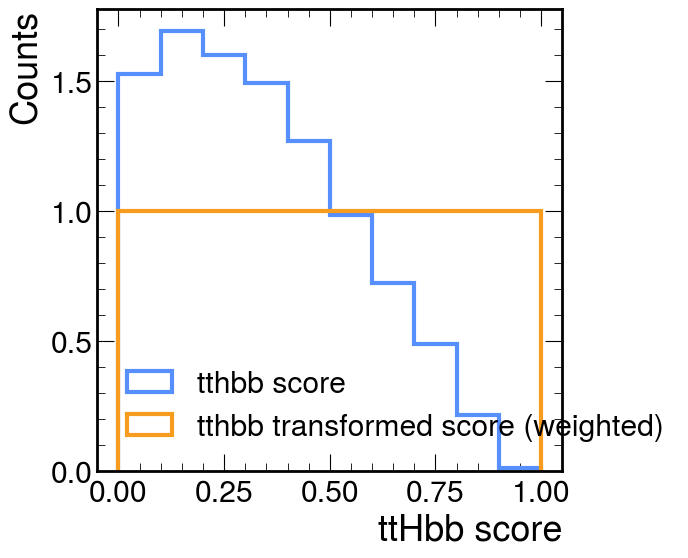

In [12]:
fig, ax = plt.subplots(1,1, figsize=[6,6])
ax.hist(pred_labels["tthbb"][is_tthbb], weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", linewidth=3, label="tthbb score", density=True)
ax.hist(pred_labels_transformed["tthbb"][is_tthbb], weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", linewidth=3, label="tthbb transformed score (weighted)", density=True)
ax.legend(loc='best');
ax.set_xlabel("ttHbb score")
ax.set_ylabel("Counts")

In [13]:
mask_ttbb_CR = get_cr_mask(pred_labels_transformed, tthbb_transformed_min, tthbb_transformed_max, ttlf_max)
mask_ttbb_SR = get_sr_mask(pred_labels_transformed, tthbb_transformed_min, tthbb_transformed_max, ttlf_max)

In [14]:
mask_ttbb_CR.shape

(9464135,)

In [15]:
df.events.fields

['ht',
 'bjets_ht',
 'lightjets_ht',
 'drbb_min',
 'detabb_min',
 'dphibb_min',
 'drbb_avg',
 'mbb_closest',
 'mbb_min',
 'mbb_max']

In [16]:
# get 3rd bjet pt, eta
bjet_pt_3 = df.BJetGood.pt[:,2]
bjet_eta_3 = df.BJetGood.eta[:,2]

In [17]:
# classes for classifier: true(1) if data or other bkg, false(0) ttbb
is_data = ak.to_numpy(ak.where(df.dctr == 1, ak.ones_like(df.dctr), ak.zeros_like(df.dctr))) == 1
is_data

array([ True,  True,  True, ...,  True, False,  True])

In [18]:
data = []
for f in df.events.fields:
    data.append(ak.to_numpy(df.events[f]))
#ak.to_numpy(df.events, allow_missing=False)
data

[array([318.95047712, 386.42113079, 514.13447394, ..., 205.53180683,
        449.27623439, 289.63848489]),
 array([271.21084219, 241.3154983 , 245.53757007, ..., 162.34133697,
        393.58211548, 175.62139548]),
 array([ 47.73963493, 145.10563249, 268.59690387, ...,  43.19046986,
         55.69411891, 114.01708941]),
 array([1.55690324, 1.22351909, 1.6172291 , ..., 1.41314268, 1.02601624,
        1.29259741]),
 array([0.42565918, 0.75738525, 0.56188965, ..., 0.3605957 , 0.04223633,
        0.70678711]),
 array([0.76072431, 0.21875   , 1.25291181, ..., 0.6171875 , 1.02514648,
        0.71838379]),
 array([2.53573577, 1.6921161 , 2.42226823, ..., 2.41196632, 2.29444249,
        2.10032225]),
 array([113.33169477, 100.78795256, 138.04931872, ...,  86.71056854,
         82.37740175,  83.5296758 ]),
 array([113.33169477,  88.1292897 , 138.04931872, ...,  84.32704911,
         82.37740175,  83.5296758 ]),
 array([285.1851351 , 134.1489332 , 210.28683842, ..., 128.31787537,
        420.7023

In [19]:
dctr_inputs = np.stack(data).T #row per event [batch,feature]

In [20]:
target = ak.to_numpy(ak.where(df.ttbb == 1, ak.zeros_like(df.ttbb), ak.ones_like(df.ttbb)))
#target

In [21]:
weights = ak.to_numpy(df.event.weight)

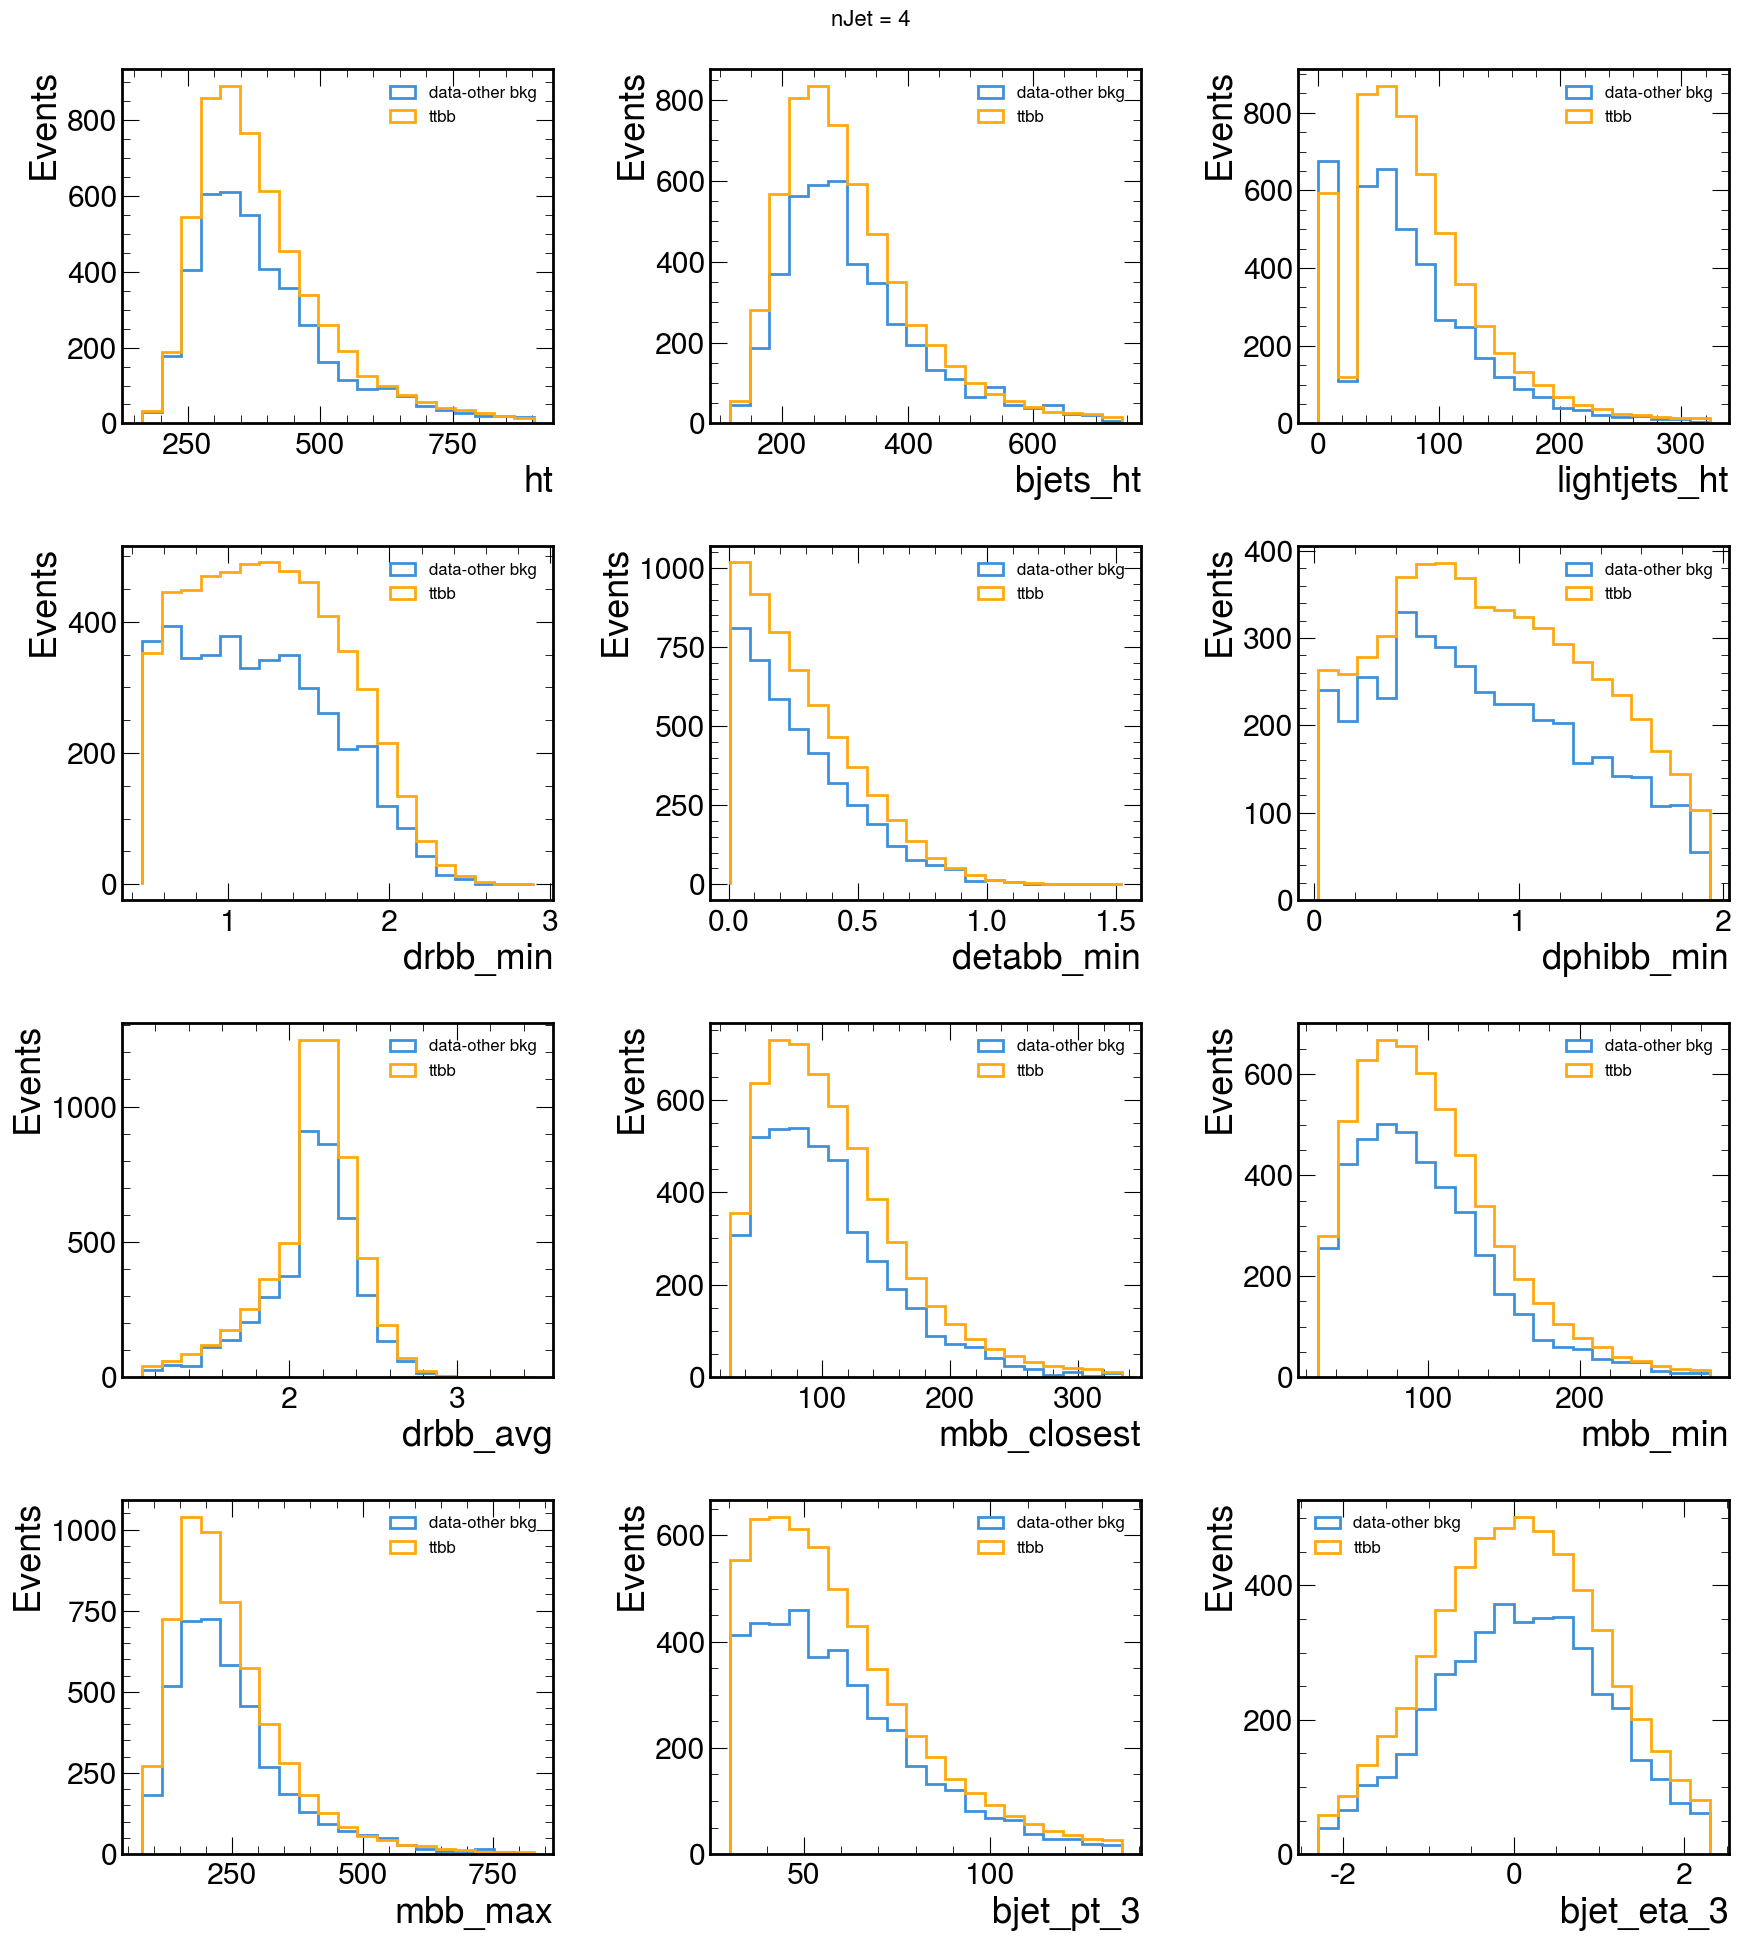

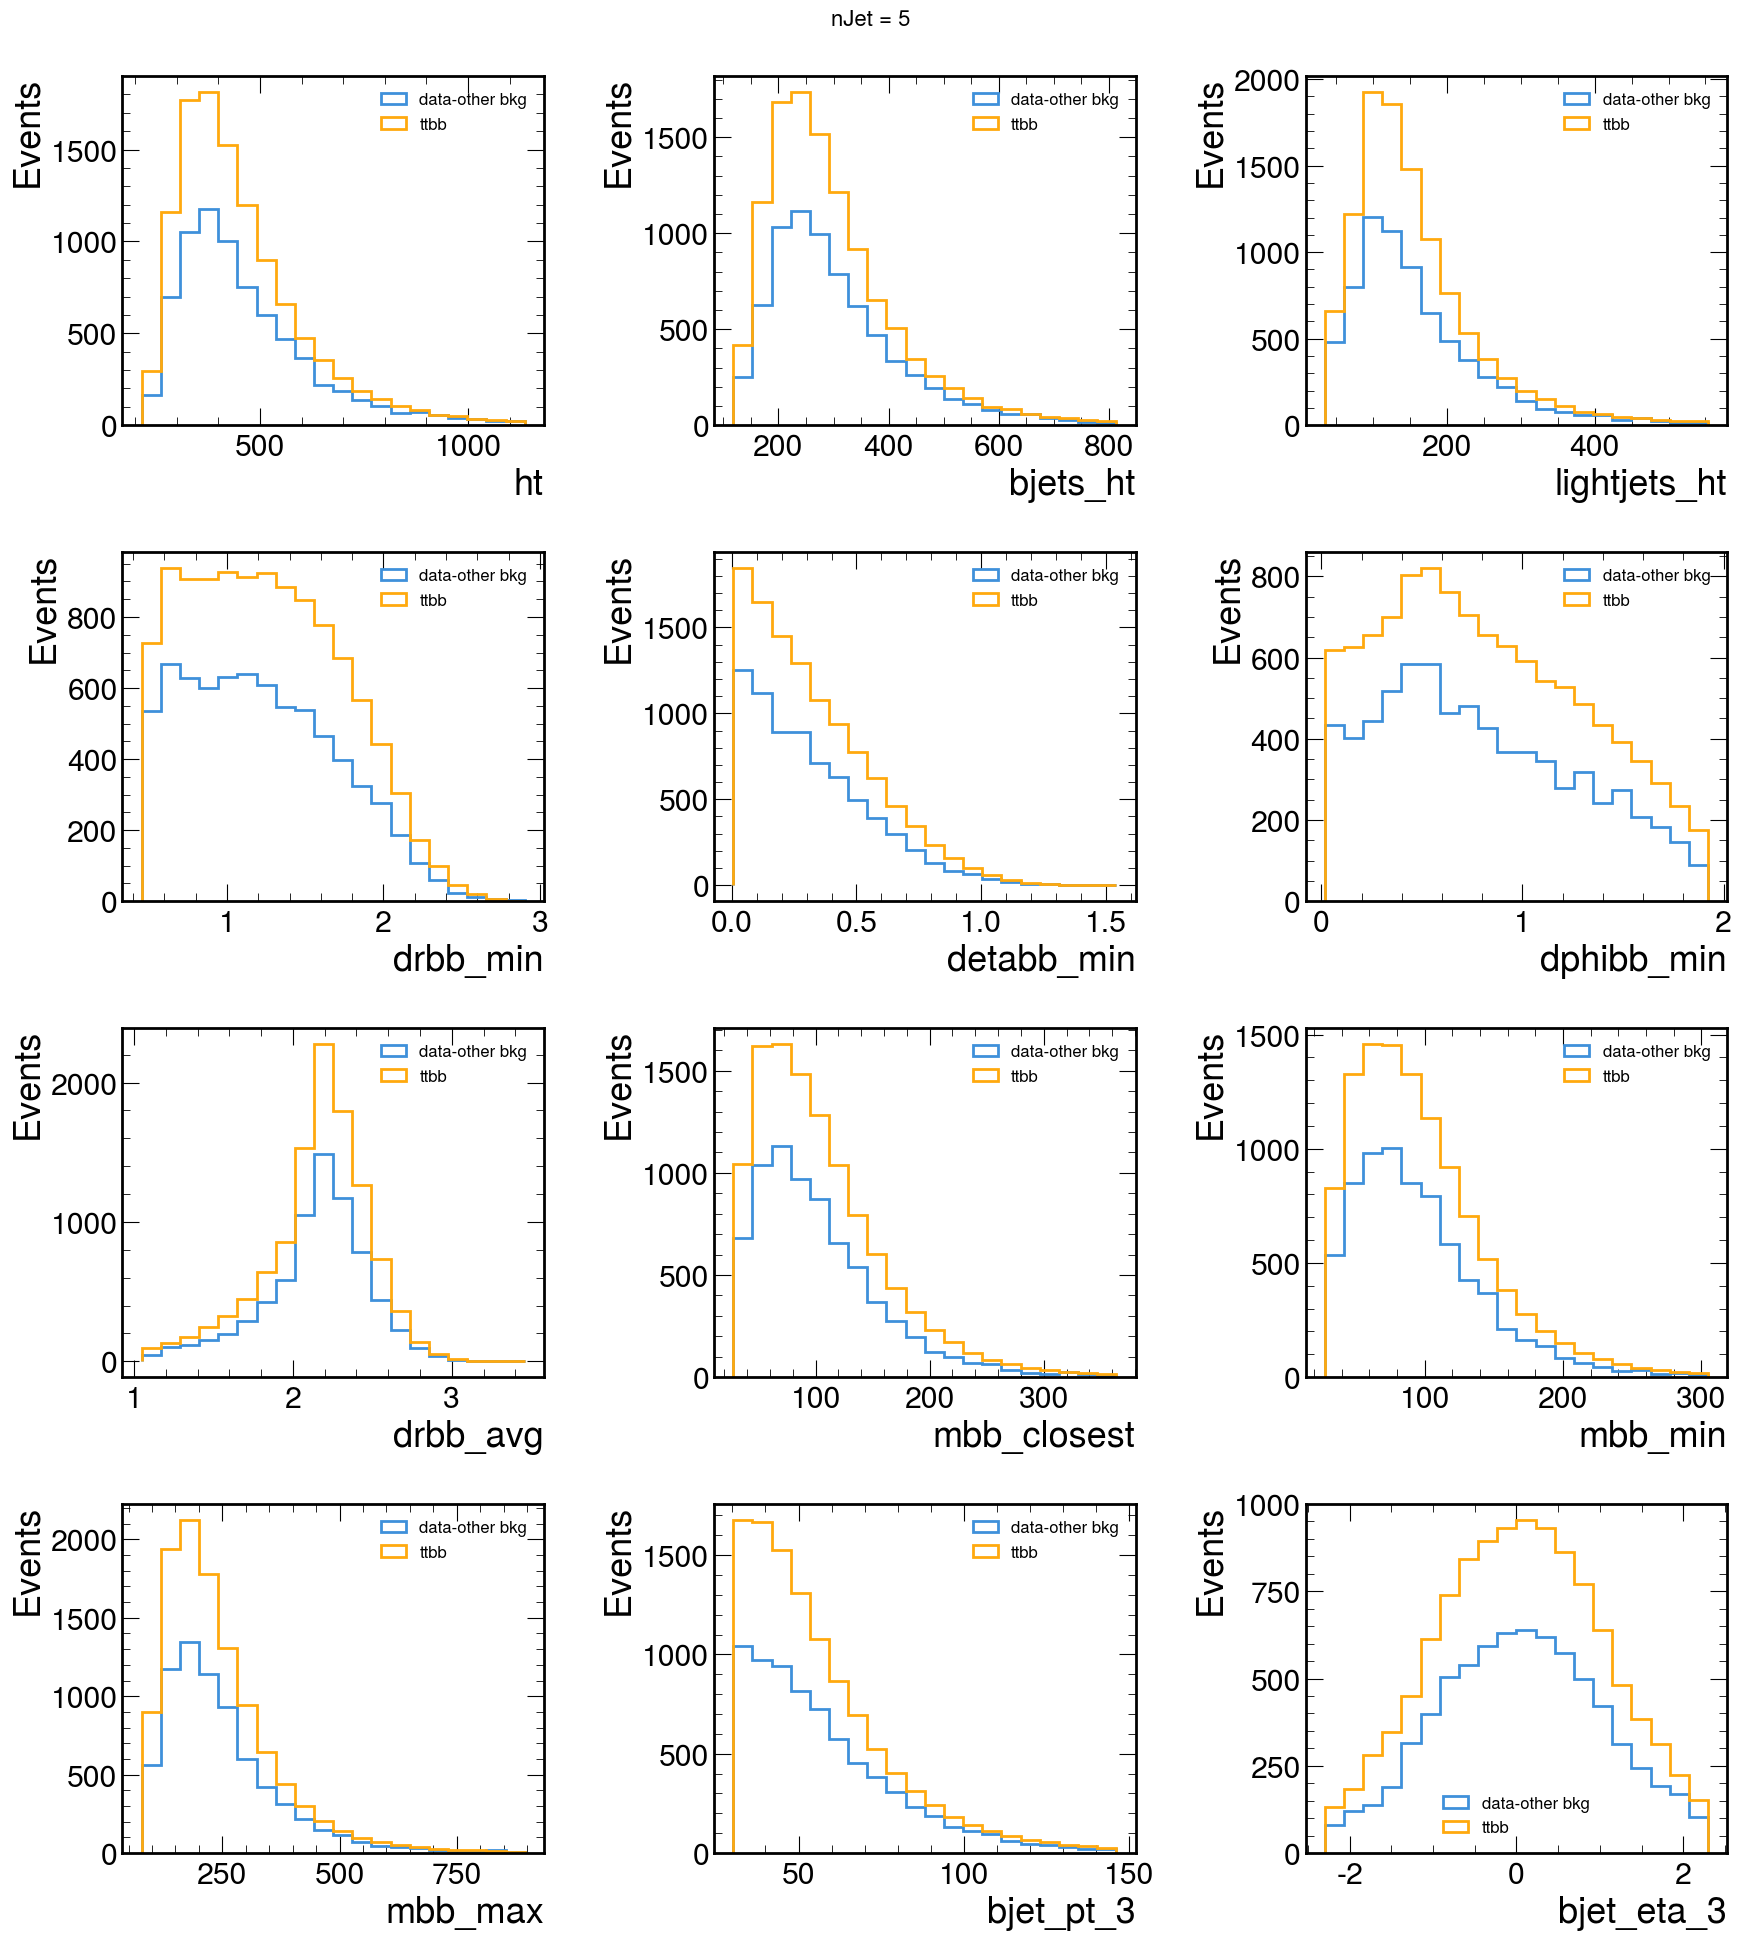

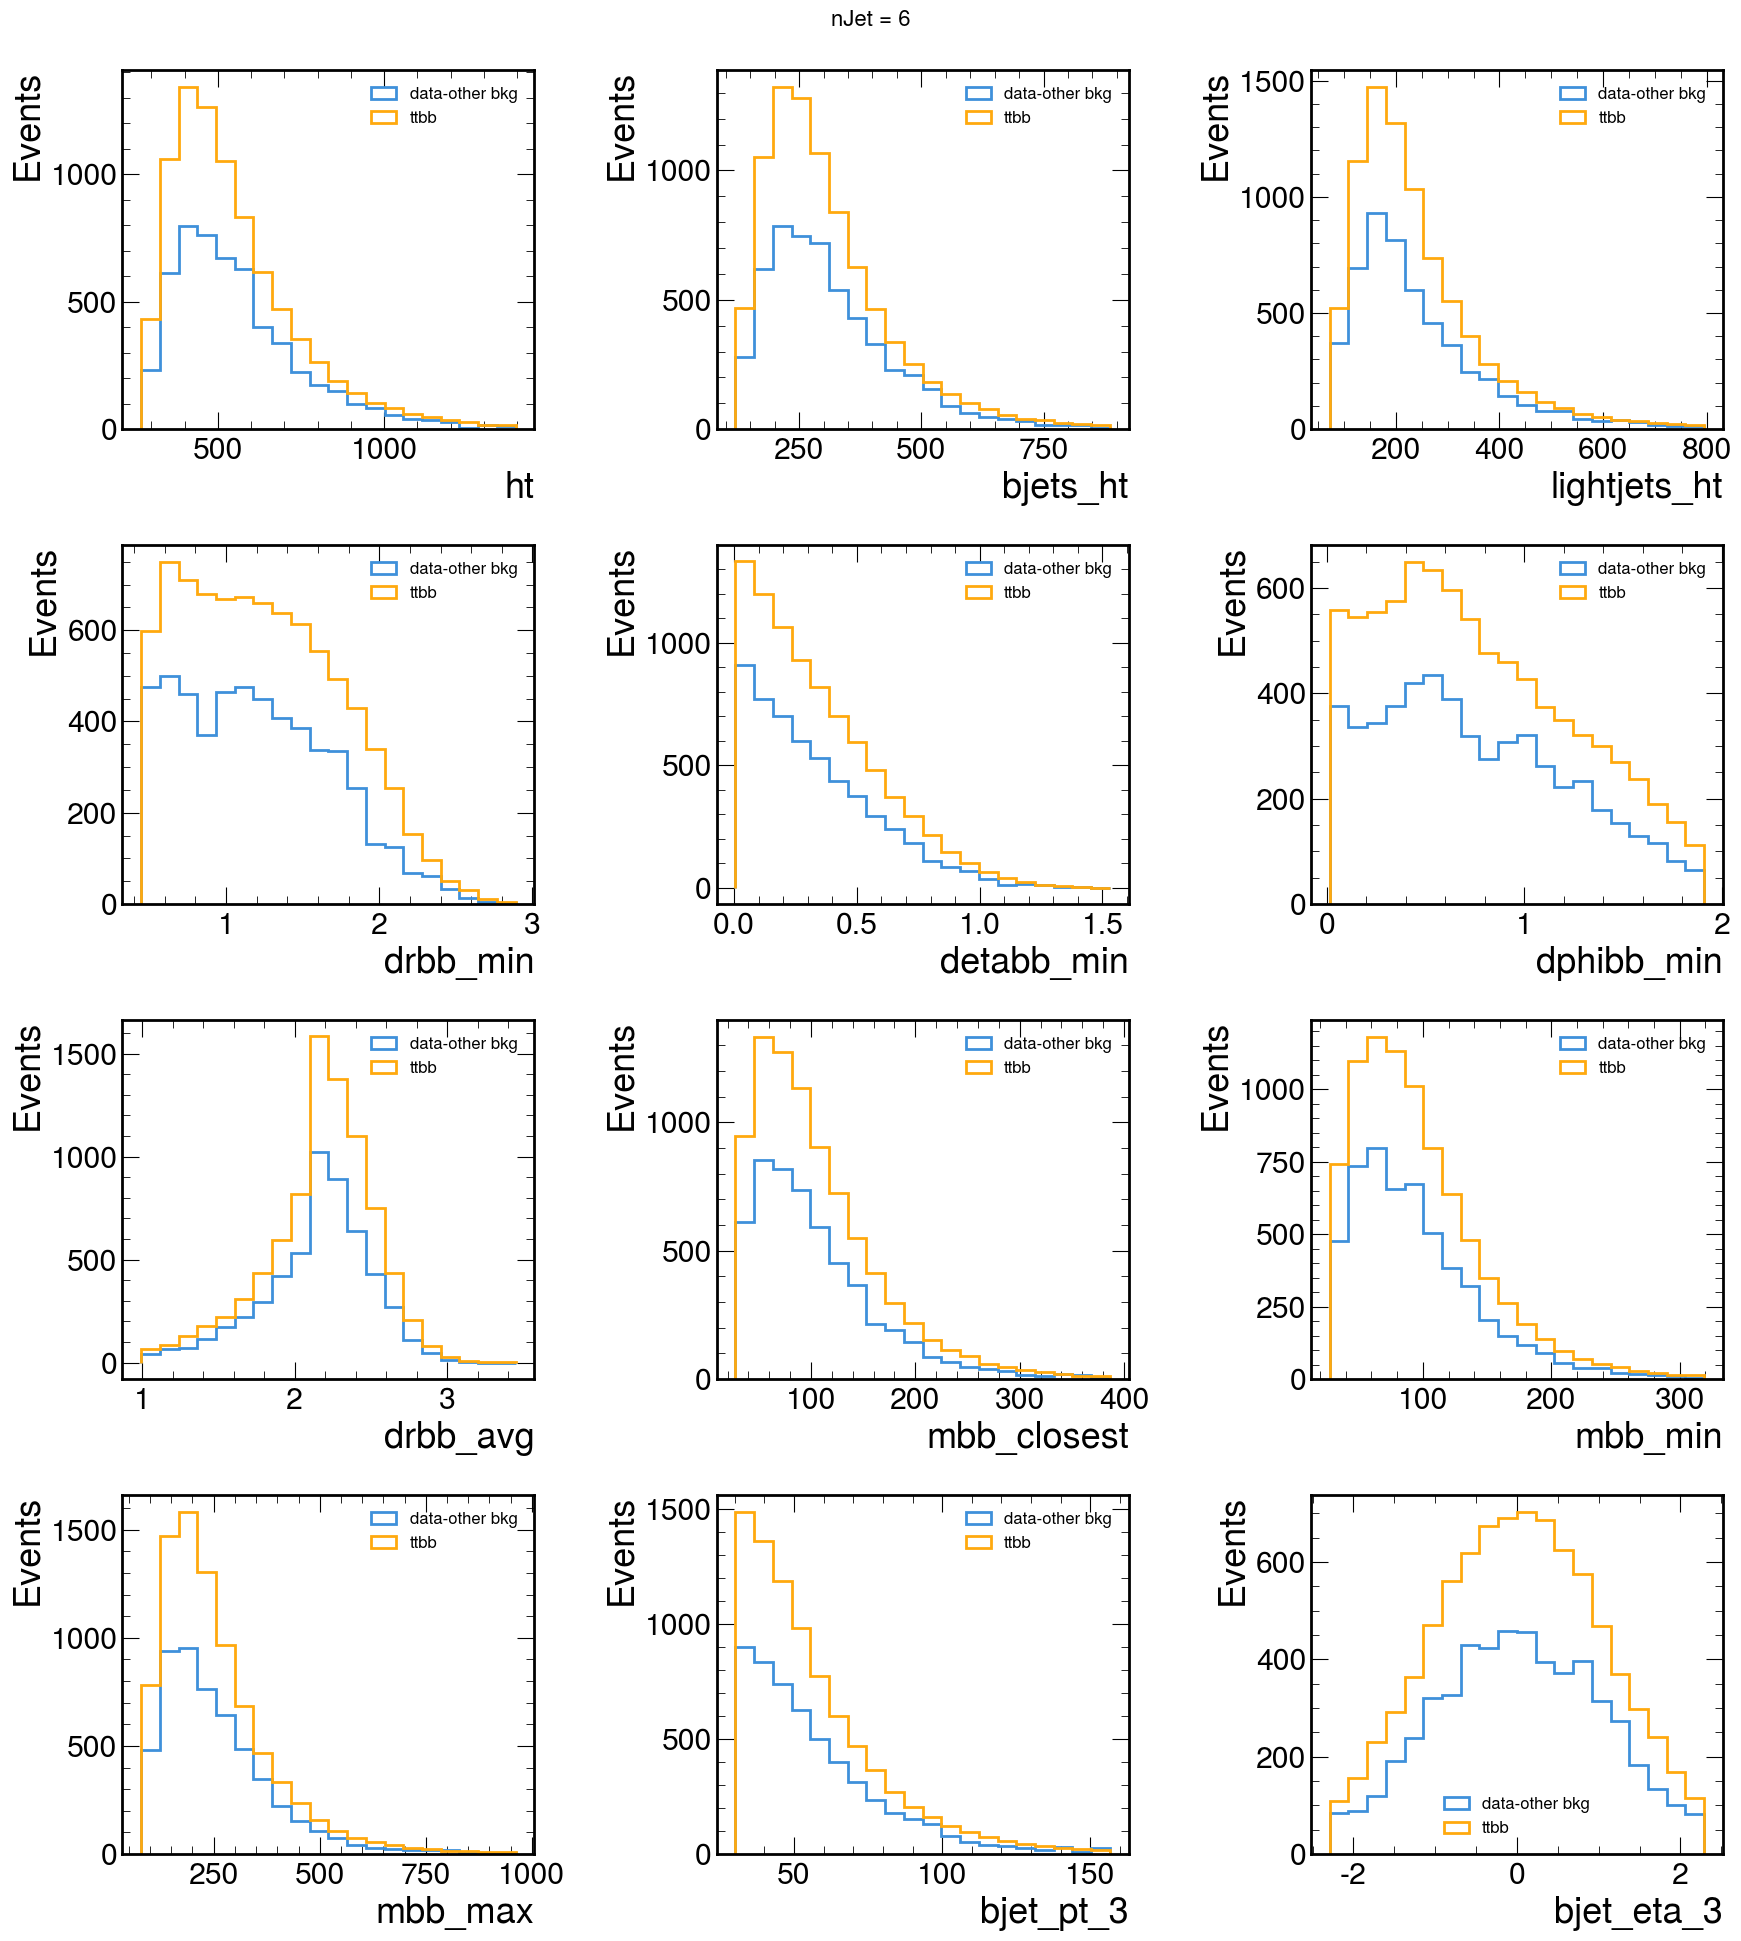

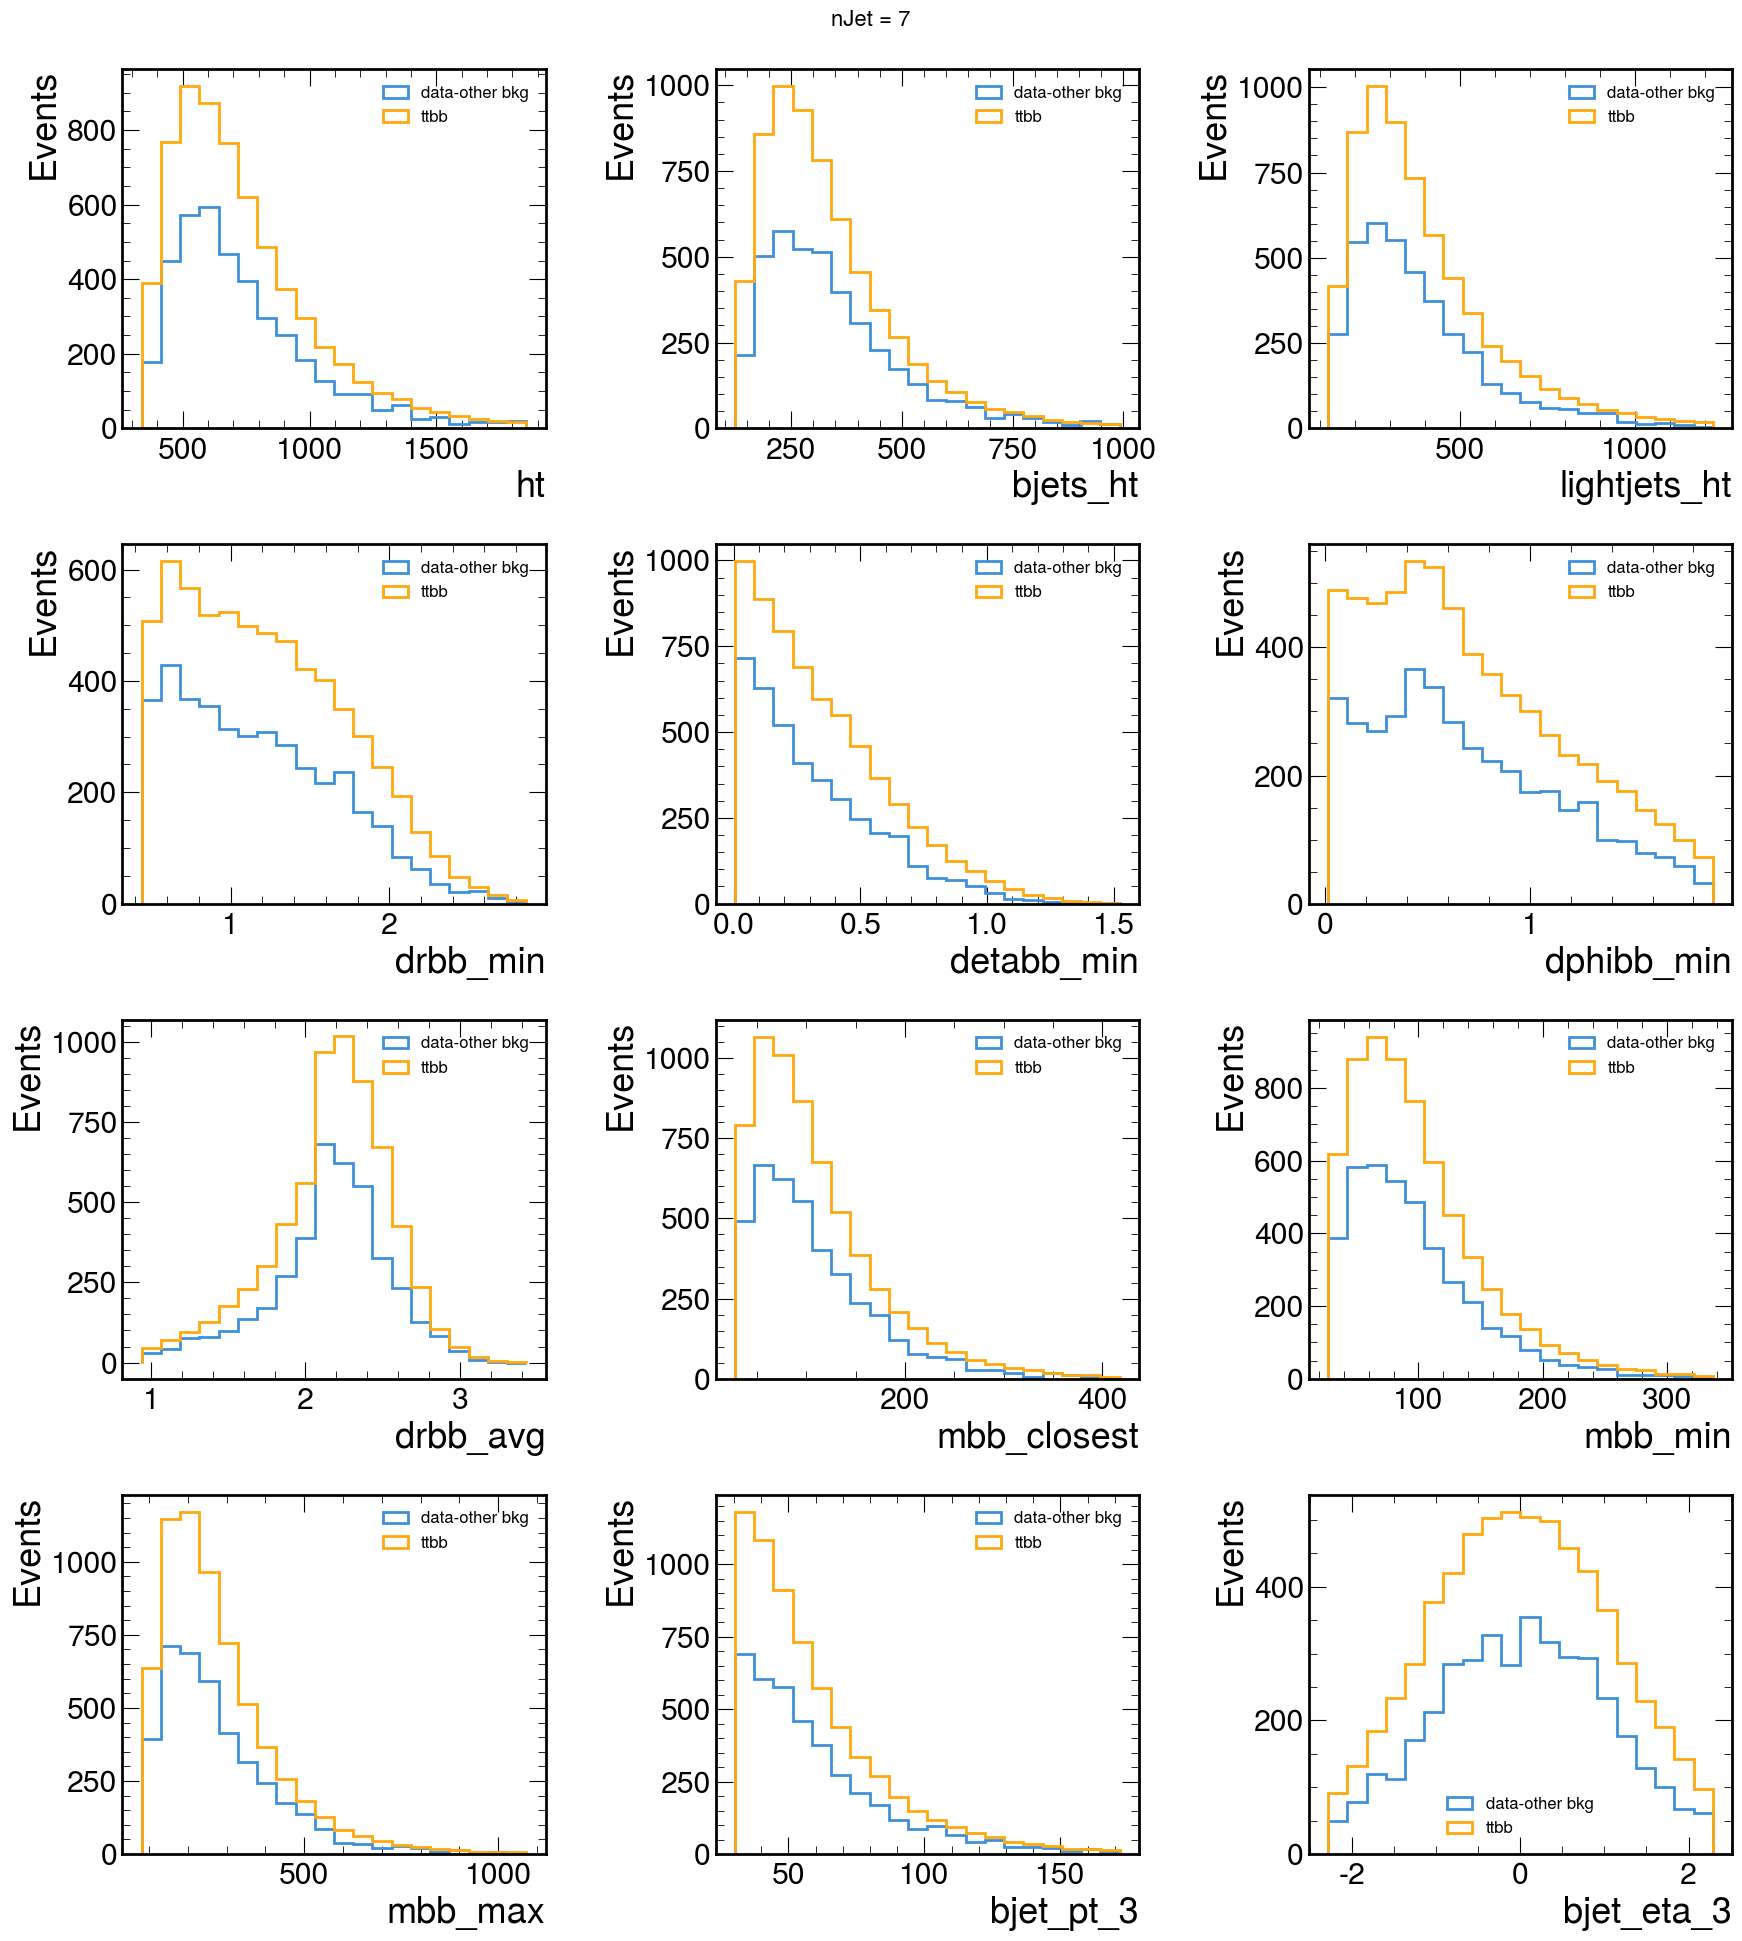

In [22]:
# Reproduce the same plots for each jet multiplicity
njet = ak.num(df.JetGood)
fields = list(df.events.fields) + ["bjet_pt_3", "bjet_eta_3"]
n_fields = len(fields)
ncols = 3
nrows = (n_fields + ncols - 1) // ncols

for nj in range(4, 8):
    if nj == 7:
        mask_nj = ak.to_numpy(njet >= nj)
    else:
        mask_nj = ak.to_numpy(njet == nj)
    
    fig, axes = plt.subplots(nrows, ncols, figsize=[6*ncols, 5*nrows])
    axes = axes.flatten()
    
    for i, field in enumerate(fields):
        ax = axes[i]
        if field == "bjet_pt_3":
            var = bjet_pt_3
        elif field == "bjet_eta_3":
            var = bjet_eta_3
        else:
            var = df.events[field]
        
        # Compute range from data (using njet selection)
        var_np = ak.to_numpy(var[mask_nj])
        vmin, vmax = np.nanpercentile(var_np, [1, 99])
        
        # Combined masks: njet_mask AND (mask_dctr or ~mask_dctr)
        mask_dctr_nj = is_data & mask_nj & mask_ttbb_CR
        mask_ttbb_nj = (~is_data) & mask_nj & mask_ttbb_CR
        
        ax.hist(var[mask_dctr_nj], weights=weights[mask_dctr_nj], bins=20, range=(vmin, vmax), 
                histtype="step", linewidth=2, color=CMAP_10[0], label="data-other bkg")
        ax.hist(var[mask_ttbb_nj], weights=weights[mask_ttbb_nj], bins=20, range=(vmin, vmax), 
                histtype="step", linewidth=2, color=CMAP_10[1], label="ttbb")
        ax.set_xlabel(field)
        ax.set_ylabel("Events")
        ax.legend(fontsize=12)
    
    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    
    fig.suptitle(f"nJet = {nj}", fontsize=16)
    fig_name = os.path.join(save_folder, f"dctr_input_variables_{nj}Jets.png")
    plt.savefig(fig_name, dpi=300)
    plt.tight_layout()
    plt.show()

In [23]:
data = []
for f in df.events.fields:
    data.append(ak.to_numpy(df.events[f][mask_ttbb_CR]))
data
data.append(ak.to_numpy(bjet_pt_3[mask_ttbb_CR]))
data.append(ak.to_numpy(bjet_eta_3[mask_ttbb_CR]))

In [24]:
data_sr = []
for f in df.events.fields:
    data_sr.append(ak.to_numpy(df.events[f][mask_ttbb_SR]))
data_sr.append(ak.to_numpy(bjet_pt_3[mask_ttbb_SR]))
data_sr.append(ak.to_numpy(bjet_eta_3[mask_ttbb_SR]))

In [25]:
mask_ttbb_SR.shape

(9464135,)

In [54]:
~is_data

array([False, False, False, ..., False,  True, False])

In [ ]:
is_ttbb  = (df.dctr == 0)

dctr_inputs = np.stack(data).T #row per event [batch,feature]

# true if data or other bkg 0 ttbb with mask for ttbb cr
target = ak.to_numpy(ak.where(df.dctr == 1, ak.ones_like(df.dctr), ak.zeros_like(df.dctr)))[mask_ttbb_CR]

In [28]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import torch

# Standard way to normalize inputs using scikit-learn before converting them to tensors. 
# This ensures your data has a mean of 0 and a standard deviation of 1, which helps the model converge faster.

# 1. Dummy Data
x_numpy = dctr_inputs.astype(np.float32) 

# 2. Initialize and Fit Standard Scaler
scaler = StandardScaler()

# fit_transform calculates mean/std AND applies the transformation
x_scaled = scaler.fit_transform(x_numpy)
# I apply the same scaling used in the DCTR for the CR
x_scaled_sr = scaler.transform(dctr_inputs_sr.astype(np.float32))

print(f"Original Mean: {x_numpy.mean():.2f}") # e.g., ~50.00
print(f"Scaled Mean:   {x_scaled.mean():.2f}") # e.g., ~0.00


Original Mean: 133.71
Scaled Mean:   0.00


In [29]:
target.shape

(1079677,)

In [30]:
target.shape

(1079677,)

In [31]:
njet

<Array [4, 5, 5, 8, 4, 7, ... 4, 4, 5, 4, 4, 5] type='9464135 * int64'>

In [32]:
counts_ttbb, edges = np.histogram(ak.to_numpy(njet[mask_ttbb_CR])[target == 0], weights=weights[mask_ttbb_CR][target == 0], bins=[4,5,6,7,25],)
counts_data, edges = np.histogram(ak.to_numpy(njet[mask_ttbb_CR])[target == 1], weights=weights[mask_ttbb_CR][target == 1], bins=[4,5,6,7,25])

(array([4179.66027033, 7326.19524511, 5427.31300018, 4004.84398844]),
 array([ 4.,  5.,  6.,  7., 25.]),
 [<matplotlib.patches.Polygon at 0x7f17142e7390>])

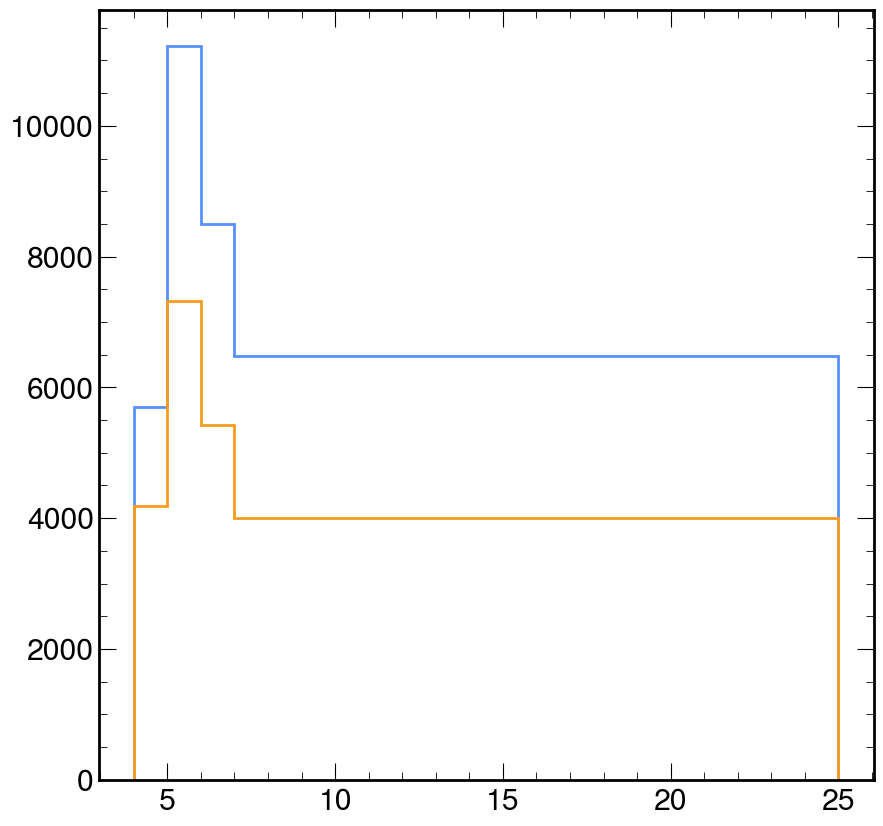

In [33]:
plt.hist(ak.to_numpy(njet[mask_ttbb_CR])[target == 0], weights=weights[mask_ttbb_CR][target == 0], bins=[4,5,6,7,25], histtype="step", linewidth=2, label="ttbb")
plt.hist(ak.to_numpy(njet[mask_ttbb_CR])[target == 1], weights=weights[mask_ttbb_CR][target == 1], bins=[4,5,6,7,25], histtype="step", linewidth=2, label="data")

In [34]:
reweight_N_jets_factors = counts_data/ counts_ttbb
reweight_N_jets_factors

array([0.73240201, 0.65322294, 0.63877062, 0.61792698])

In [35]:
edges

array([ 4,  5,  6,  7, 25])

In [ ]:
rew_N_jets_ttbb = np.ones((target==0).sum())
rew_N_jets_ttbb[ak.to_numpy(njet[mask_ttbb_CR][target == 0]) == 4] = reweight_N_jets_factors[0]
rew_N_jets_ttbb[ak.to_numpy(njet[mask_ttbb_CR][target == 0]) == 5] = reweight_N_jets_factors[1]
rew_N_jets_ttbb[ak.to_numpy(njet[mask_ttbb_CR][target == 0]) == 6] = reweight_N_jets_factors[2]
rew_N_jets_ttbb[ak.to_numpy(njet[mask_ttbb_CR][target == 0]) >= 7] = reweight_N_jets_factors[3]

(array([4179.66027033, 7326.19524511, 5427.31300018, 4004.84398844]),
 array([ 4.,  5.,  6.,  7., 25.]),
 [<matplotlib.patches.Polygon at 0x7f16dd5760d0>])

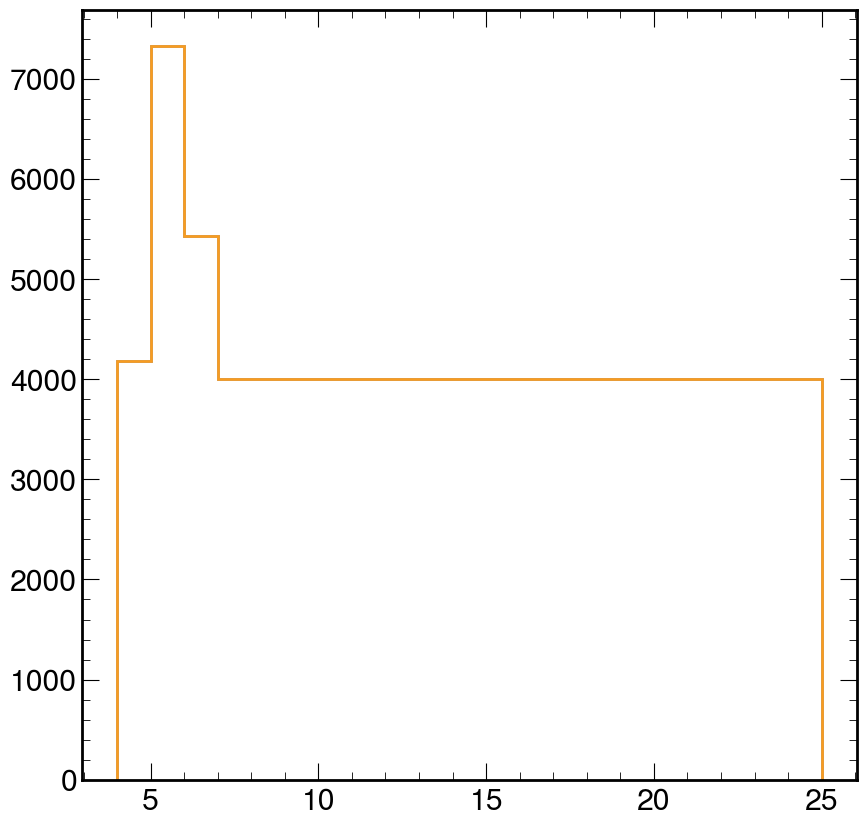

In [ ]:
plt.hist(ak.to_numpy(njet[mask_ttbb_CR])[target == 0], weights=weights[mask_ttbb_CR][target == 0]*rew_N_jets_ttbb, bins=[4,5,6,7,25], histtype="step", linewidth=2, label="ttbb")
plt.hist(ak.to_numpy(njet[mask_ttbb_CR])[target == 1], weights=weights[mask_ttbb_CR][target == 1], bins=[4,5,6,7,25], histtype="step", linewidth=2, label="data")

In [ ]:
training_weight = weights[mask_ttbb_CR].copy()
training_weight[target == 0] = training_weight[target == 0] * rew_N_jets_ttbb

In [39]:
training_weight.shape

(1079677,)

In [40]:
x_scaled.shape[0] / 2048

527.18603515625

In [41]:
w_tensor_adv.shape 

NameError: name 'w_tensor_adv' is not defined

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# add weight as 3rd vector
# 2. Convert to PyTorch Tensors
x_tensor = torch.from_numpy(x_scaled)
y_tensor = torch.from_numpy(target)
w_tensor = torch.from_numpy(training_weight)

# 3. Create a Dataset
# TensorDataset wraps tensors so index i returns tuple (X[i], y[i], w[i])
dataset = TensorDataset(x_tensor, y_tensor, w_tensor)

# 4. Train and validation split on the dataset
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [0.8, 0.2], )

# 5. Create DataLoaders for train and validation
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4096, shuffle=False)

# 6. Iterate through the loader (simulating a training loop)
print("Starting iteration...")
print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

Starting iteration...
Train batches: 844, Val batches: 53


In [43]:
# Simple DNN

from torch import nn 

class DCTRNet(nn.Module):
    def __init__(self, input_dim, hidden_net=[64,64,64], hidden_net_classifier=[64,64], hidden_net_adv=[64,64]):
        super(DCTRNet, self).__init__()
        layers = []
        for h_dim in hidden_net:
            layers.append(nn.Linear(input_dim, h_dim))
            layers.append(nn.ReLU())
            input_dim = h_dim

        layers.append(nn.Linear(input_dim, input_dim))  # Final layer for binary classification
        #layers.append(nn.Sigmoid())  # Output between 0 and 1 for binary classification
        self.pre_model = nn.Sequential(*layers)
        self.features_dim = hidden_net[-1]

        input_dim = self.features_dim
        layers_classifier = []
        for h_dim in hidden_net_classifier:
            layers_classifier.append(nn.Linear(input_dim, h_dim))
            layers_classifier.append(nn.ReLU())
            input_dim = h_dim
        layers_classifier.append(nn.Linear(input_dim, 1))  # Final layer for binary classification
        self.classifier = nn.Sequential(*layers_classifier)

        input_dim = self.features_dim
        adv_layers = []
        for h_dim in hidden_net_adv:
            adv_layers.append(nn.Linear(input_dim, h_dim))
            adv_layers.append(nn.ReLU())
            input_dim = h_dim
        adv_layers.append(nn.Linear(input_dim, 1))  # Final layer for binary classification
        self.model_adv = nn.Sequential(*adv_layers)
    
    def forward(self, x, return_features=False, run_adv=False):
        features = self.pre_model(x)
        if run_adv:
            adv_output = self.model_adv(features)
            if return_features:
                return adv_output, features
            return adv_output
        else:
            if return_features:
                return self.classifier(features), features
            return self.classifier(features)



In [44]:
model = DCTRNet(input_dim=x_tensor.shape[1], hidden_net=[64,64,12], hidden_net_classifier=[32,32], hidden_net_adv=[64]).to("cuda")


In [45]:
model

DCTRNet(
  (pre_model): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=12, bias=True)
    (5): ReLU()
    (6): Linear(in_features=12, out_features=12, bias=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=12, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
  (model_adv): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [ ]:
x, y , w = next(iter(train_loader))

In [47]:
pred, features = model(x_sr.to("cuda"), run_adv=True, return_features=True)

In [ ]:
def train(model, n_epochs,  train_loader, val_loader, optimizer, device):
    model.train()
    
    log_loss = []
    log_val_loss = []
    for epoch in range(n_epochs):
        total_loss = 0
        for features, labels, weights in train_loader:
            features, labels, weights = features.to(device), labels.to(device), weights.to(device)
            
            optimizer.zero_grad()  # Clear gradients
            outputs = model(features).squeeze()  # Forward pass
            loss = nn.functional.binary_cross_entropy_with_logits(outputs, labels.float(), reduction='none')  # Compute loss
            #print(loss.shape)
            #print(weights.shape)
            loss = (loss * weights).sum()/weights.sum()  # Apply weights and average
            #print(loss, loss.shape)
            loss.backward()  # Backpropagation
            optimizer.step()  # Update weights
            #print(f"Batch Loss: {loss.item():.4f}")
            total_loss += loss.item()  # Accumulate weighted loss
        
        avg_loss = total_loss / len(train_loader)  # Average loss over dataset
        log_loss.append(avg_loss)
        print(f"{epoch} Training Loss: {avg_loss:.4f}")

        # validation 
        total_val_loss = 0
        model.eval()
        with torch.no_grad():
            for features, labels, weights in val_loader:
                features, labels, weights = features.to(device), labels.to(device), weights.to(device)
                outputs = model(features).squeeze()
                val_loss = nn.functional.binary_cross_entropy_with_logits(outputs, labels.float(), reduction='none')
                val_loss = (val_loss * weights).sum()/weights.sum()
                total_val_loss += val_loss.item() 
        log_val_loss.append(total_val_loss / len(val_loader))
        print(f"{epoch} Validation Loss: {total_val_loss / len(val_loader):.4f}")
        # plot every 5 epochs
        if epoch % 5 == 0:
            plt.figure()
            plt.plot(log_loss, label="Train Loss")
            plt.plot(log_val_loss, label="Validation Loss")
            plt.xlabel("Epoch")
            plt.ylabel("Loss")
            plt.title("Training and Validation Loss")
            plt.legend()
            plt.show()
        # save model every 5 epochs
        if epoch % 5 == 0:
            torch.save(model.state_dict(), f"model_epoch_{epoch}.pth")

    return log_loss, log_val_loss

0 Training Loss: 0.6940
0 Validation Loss: 0.6943


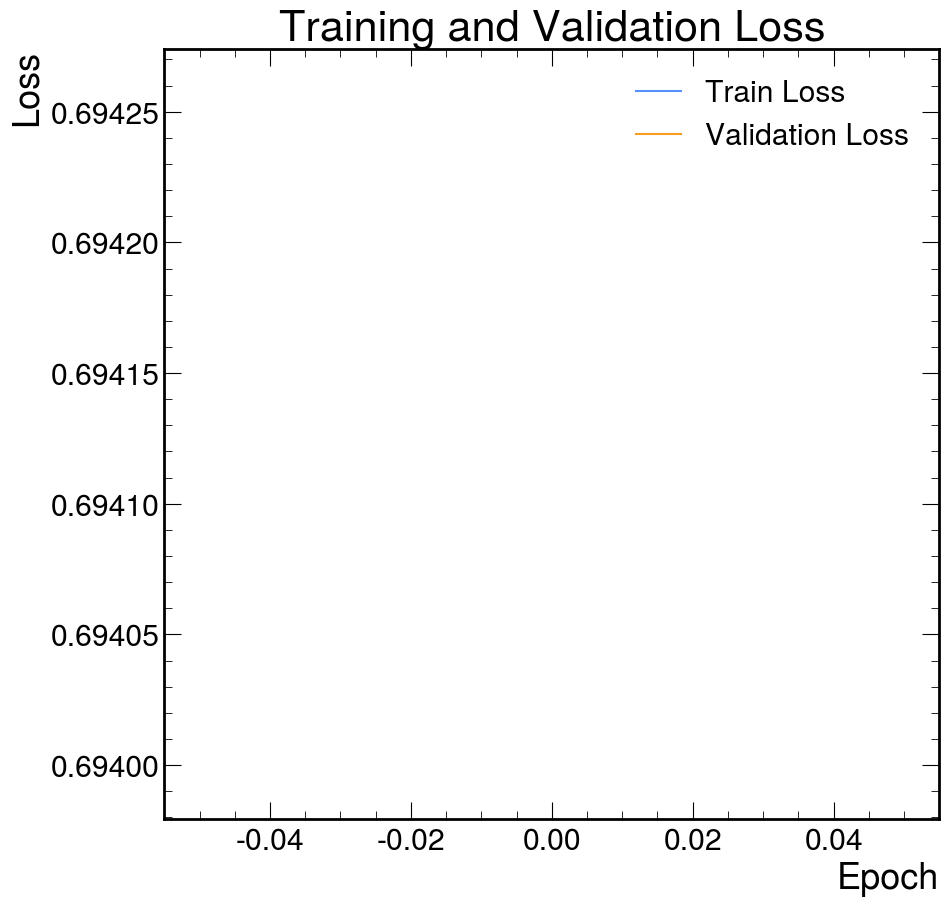

1 Training Loss: 0.6937
1 Validation Loss: 0.6940
2 Training Loss: 0.6935
2 Validation Loss: 0.6937
3 Training Loss: 0.6932
3 Validation Loss: 0.6934
4 Training Loss: 0.6930
4 Validation Loss: 0.6932
5 Training Loss: 0.6928
5 Validation Loss: 0.6930
6 Training Loss: 0.6926
6 Validation Loss: 0.6928
7 Training Loss: 0.6924
7 Validation Loss: 0.6927
8 Training Loss: 0.6923
8 Validation Loss: 0.6926
9 Training Loss: 0.6922
9 Validation Loss: 0.6925
10 Training Loss: 0.6921
10 Validation Loss: 0.6924


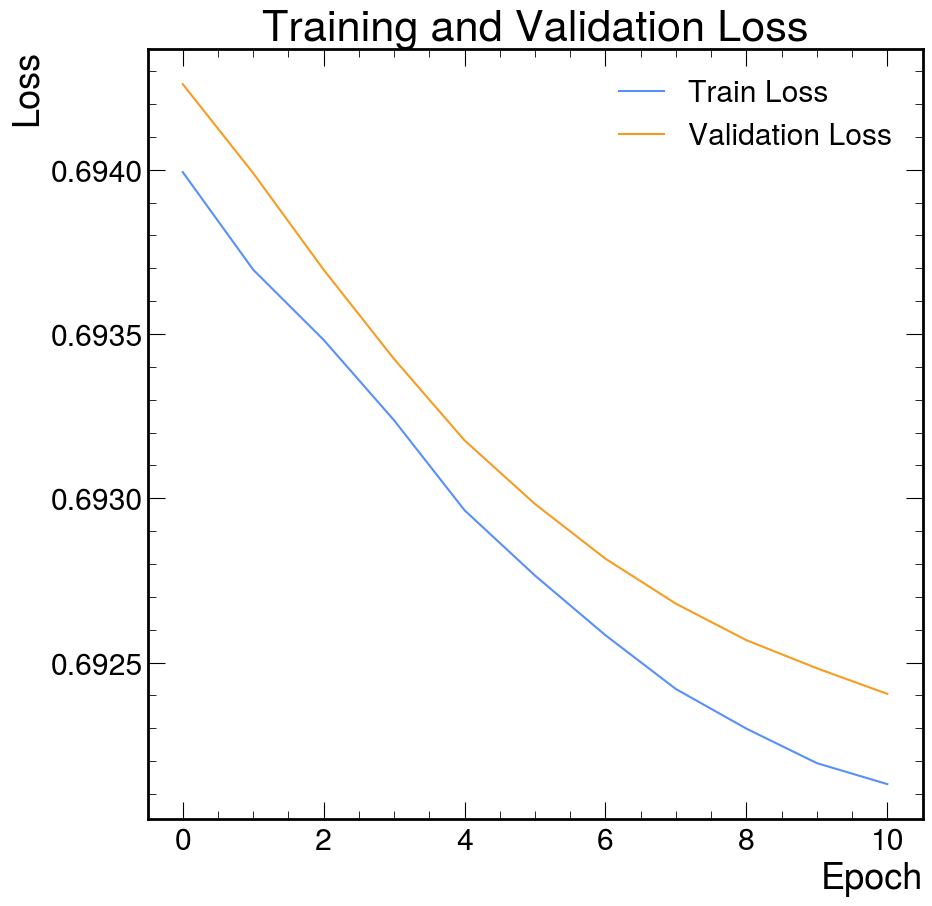

11 Training Loss: 0.6920
11 Validation Loss: 0.6923
12 Training Loss: 0.6920
12 Validation Loss: 0.6923
13 Training Loss: 0.6919
13 Validation Loss: 0.6922
14 Training Loss: 0.6919
14 Validation Loss: 0.6922
15 Training Loss: 0.6918
15 Validation Loss: 0.6922
16 Training Loss: 0.6917
16 Validation Loss: 0.6921
17 Training Loss: 0.6917
17 Validation Loss: 0.6921
18 Training Loss: 0.6916
18 Validation Loss: 0.6921
19 Training Loss: 0.6916
19 Validation Loss: 0.6920
20 Training Loss: 0.6916
20 Validation Loss: 0.6920


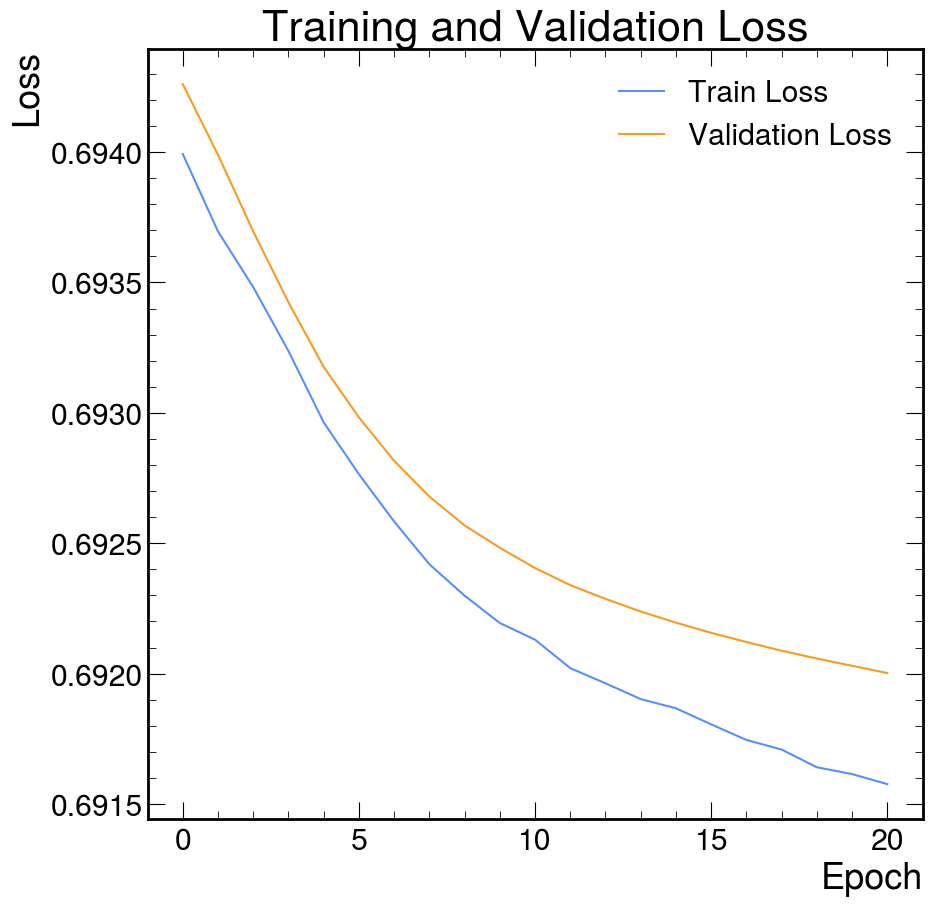

21 Training Loss: 0.6916
21 Validation Loss: 0.6920
22 Training Loss: 0.6915
22 Validation Loss: 0.6920
23 Training Loss: 0.6915
23 Validation Loss: 0.6919
24 Training Loss: 0.6914
24 Validation Loss: 0.6919
25 Training Loss: 0.6914
25 Validation Loss: 0.6919
26 Training Loss: 0.6914
26 Validation Loss: 0.6919
27 Training Loss: 0.6913
27 Validation Loss: 0.6919
28 Training Loss: 0.6914
28 Validation Loss: 0.6919
29 Training Loss: 0.6913
29 Validation Loss: 0.6918
30 Training Loss: 0.6913
30 Validation Loss: 0.6918


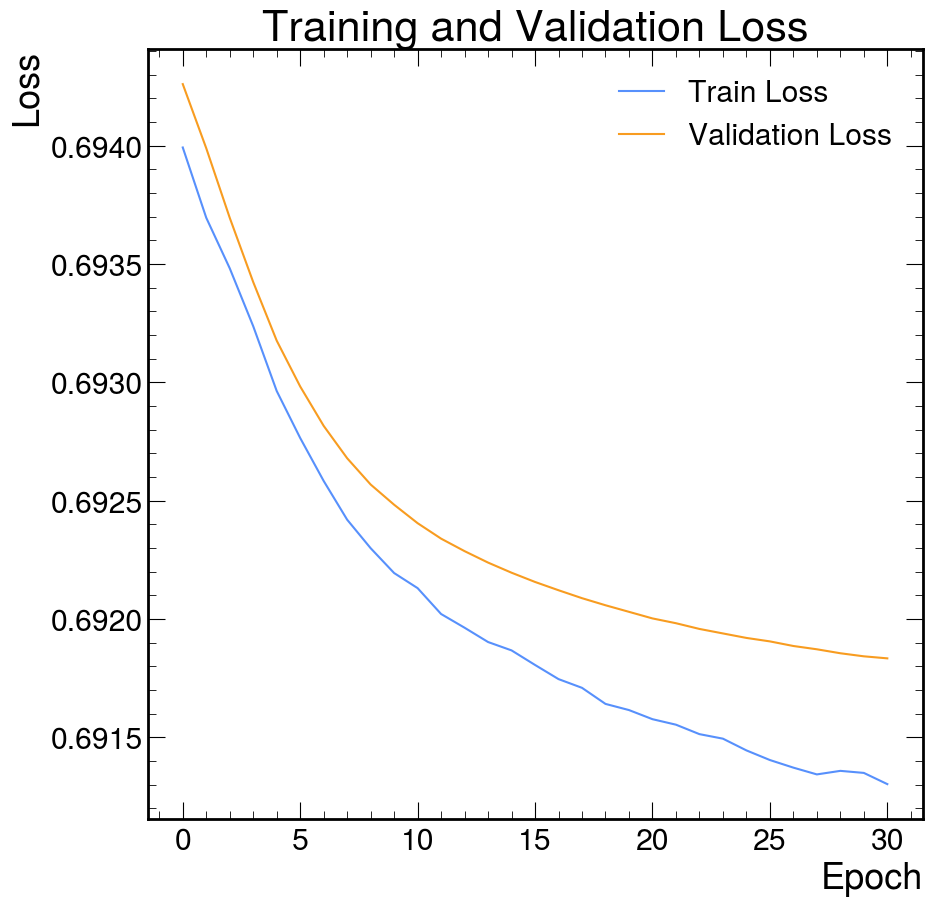

31 Training Loss: 0.6913
31 Validation Loss: 0.6918
32 Training Loss: 0.6912
32 Validation Loss: 0.6918
33 Training Loss: 0.6912
33 Validation Loss: 0.6918
34 Training Loss: 0.6912
34 Validation Loss: 0.6918
35 Training Loss: 0.6912
35 Validation Loss: 0.6918
36 Training Loss: 0.6911
36 Validation Loss: 0.6918
37 Training Loss: 0.6911
37 Validation Loss: 0.6918
38 Training Loss: 0.6911
38 Validation Loss: 0.6918
39 Training Loss: 0.6911
39 Validation Loss: 0.6917
40 Training Loss: 0.6911
40 Validation Loss: 0.6917


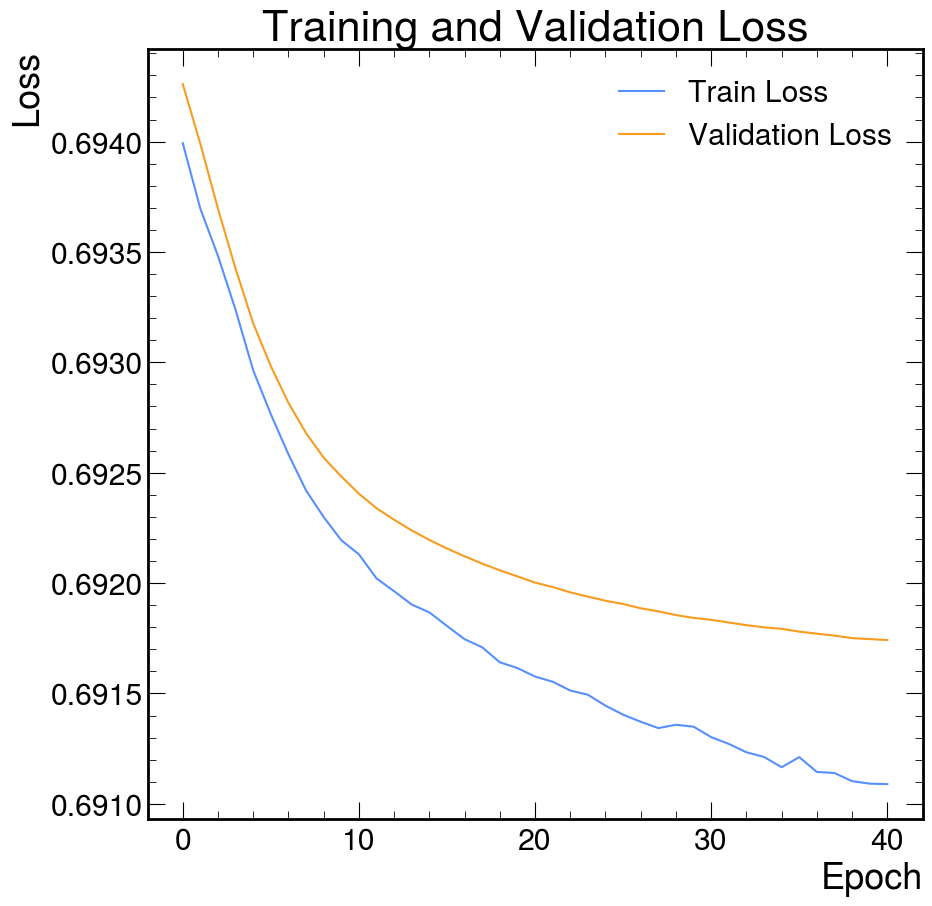

41 Training Loss: 0.6911
41 Validation Loss: 0.6917
42 Training Loss: 0.6911
42 Validation Loss: 0.6917
43 Training Loss: 0.6910
43 Validation Loss: 0.6917
44 Training Loss: 0.6910
44 Validation Loss: 0.6917
45 Training Loss: 0.6910
45 Validation Loss: 0.6917
46 Training Loss: 0.6910
46 Validation Loss: 0.6917
47 Training Loss: 0.6910
47 Validation Loss: 0.6917
48 Training Loss: 0.6909
48 Validation Loss: 0.6917
49 Training Loss: 0.6909
49 Validation Loss: 0.6917
50 Training Loss: 0.6909
50 Validation Loss: 0.6917


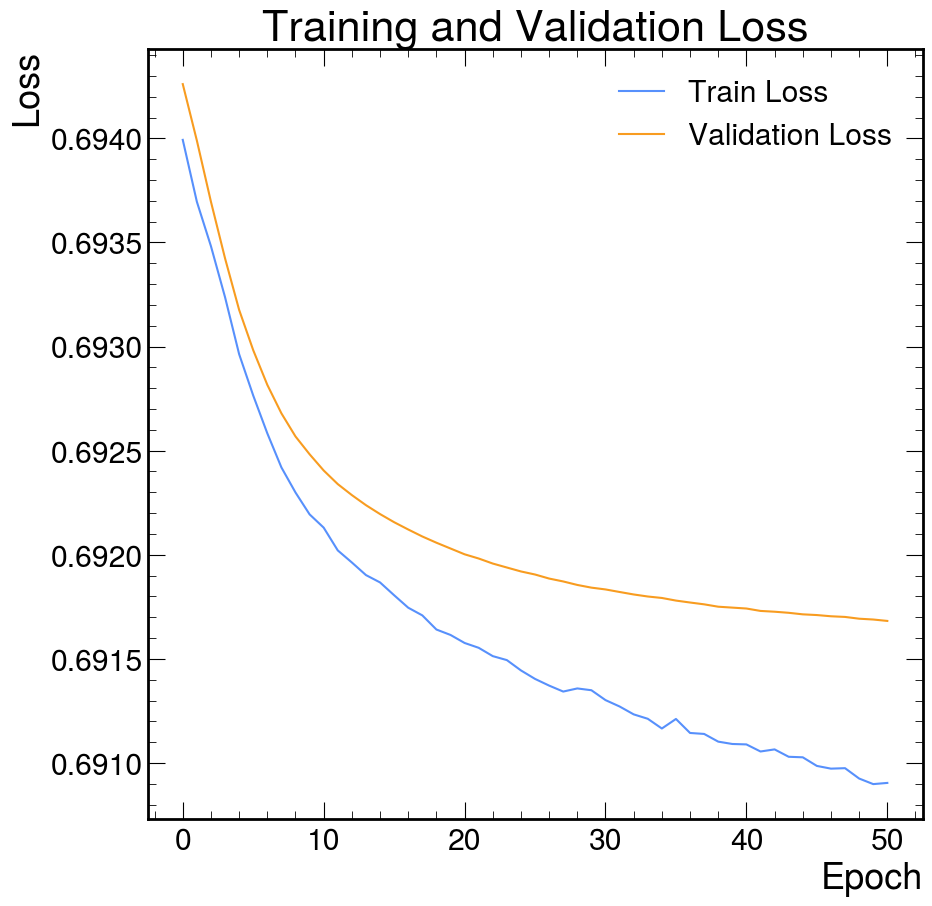

51 Training Loss: 0.6909
51 Validation Loss: 0.6917
52 Training Loss: 0.6908
52 Validation Loss: 0.6917
53 Training Loss: 0.6909
53 Validation Loss: 0.6917
54 Training Loss: 0.6908
54 Validation Loss: 0.6917
55 Training Loss: 0.6908
55 Validation Loss: 0.6917
56 Training Loss: 0.6908
56 Validation Loss: 0.6916
57 Training Loss: 0.6908
57 Validation Loss: 0.6917
58 Training Loss: 0.6908
58 Validation Loss: 0.6917
59 Training Loss: 0.6908
59 Validation Loss: 0.6916
60 Training Loss: 0.6908
60 Validation Loss: 0.6916


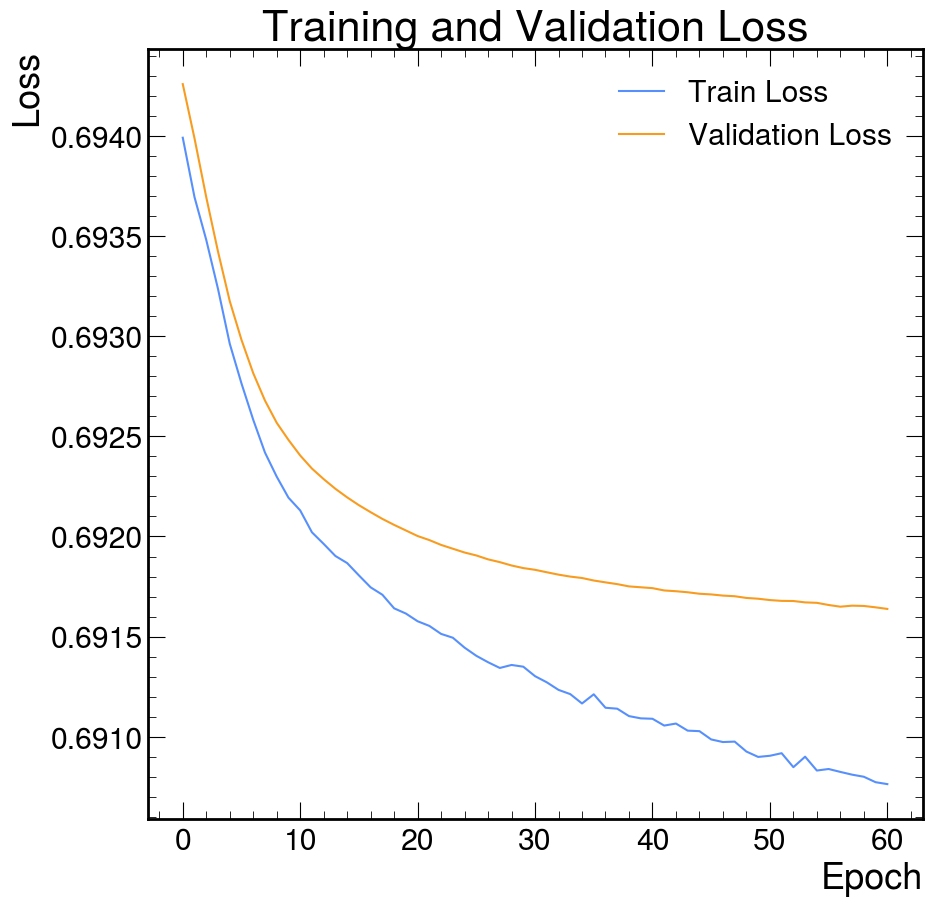

61 Training Loss: 0.6907
61 Validation Loss: 0.6916
62 Training Loss: 0.6908
62 Validation Loss: 0.6916
63 Training Loss: 0.6907
63 Validation Loss: 0.6916
64 Training Loss: 0.6907
64 Validation Loss: 0.6916
65 Training Loss: 0.6907
65 Validation Loss: 0.6916
66 Training Loss: 0.6907
66 Validation Loss: 0.6916
67 Training Loss: 0.6907
67 Validation Loss: 0.6916
68 Training Loss: 0.6907
68 Validation Loss: 0.6916
69 Training Loss: 0.6906
69 Validation Loss: 0.6916
70 Training Loss: 0.6906
70 Validation Loss: 0.6916


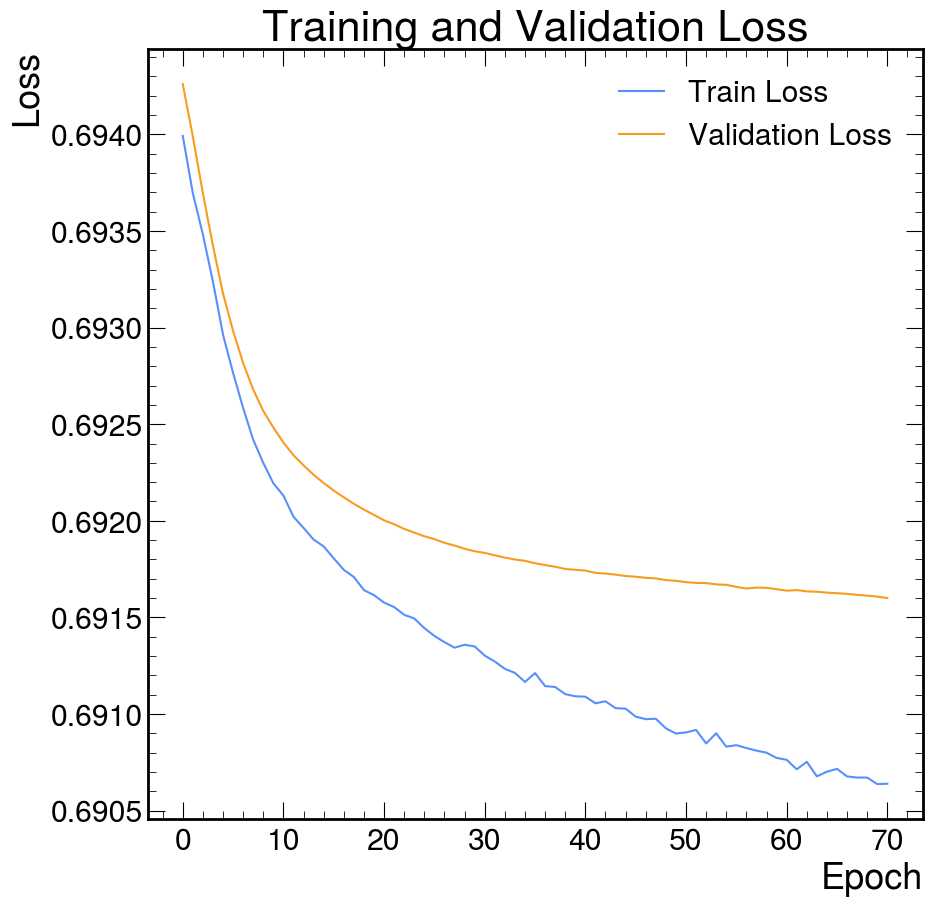

71 Training Loss: 0.6906
71 Validation Loss: 0.6916
72 Training Loss: 0.6906
72 Validation Loss: 0.6916
73 Training Loss: 0.6906
73 Validation Loss: 0.6916
74 Training Loss: 0.6905
74 Validation Loss: 0.6916
75 Training Loss: 0.6905
75 Validation Loss: 0.6916
76 Training Loss: 0.6905
76 Validation Loss: 0.6916
77 Training Loss: 0.6905
77 Validation Loss: 0.6916
78 Training Loss: 0.6905
78 Validation Loss: 0.6916
79 Training Loss: 0.6905
79 Validation Loss: 0.6916
80 Training Loss: 0.6905
80 Validation Loss: 0.6916


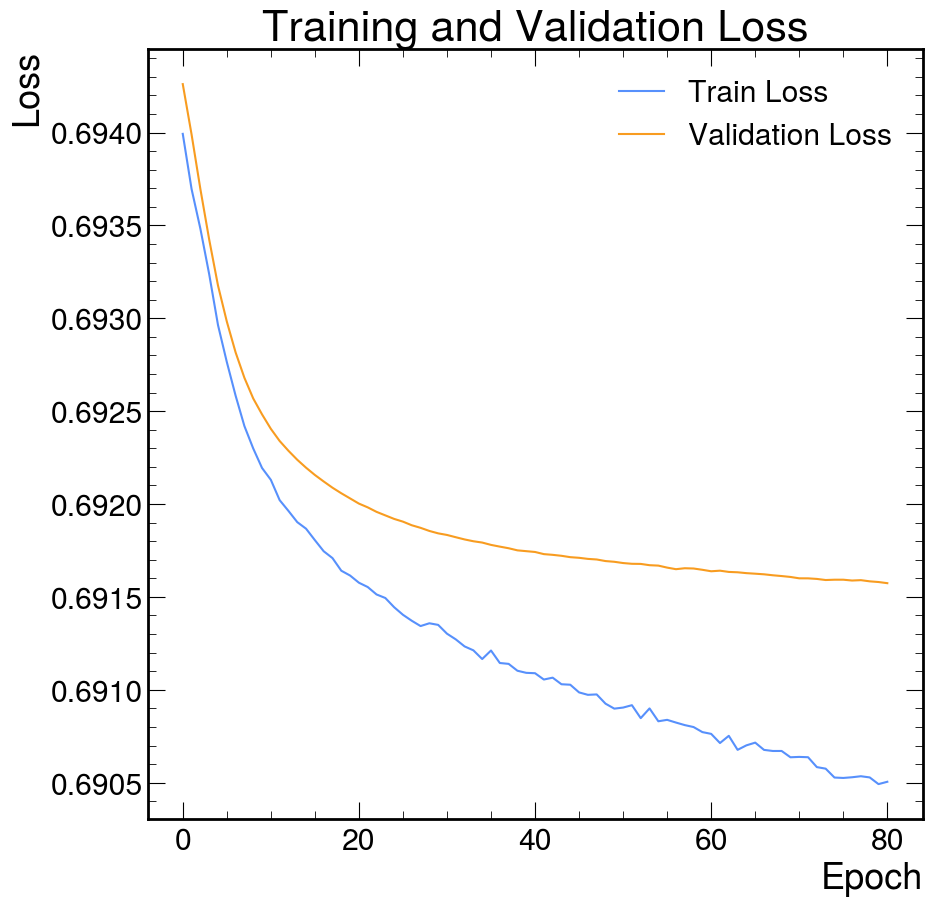

81 Training Loss: 0.6905
81 Validation Loss: 0.6916
82 Training Loss: 0.6905
82 Validation Loss: 0.6916
83 Training Loss: 0.6904
83 Validation Loss: 0.6916
84 Training Loss: 0.6905
84 Validation Loss: 0.6916
85 Training Loss: 0.6904
85 Validation Loss: 0.6916
86 Training Loss: 0.6904
86 Validation Loss: 0.6916
87 Training Loss: 0.6904
87 Validation Loss: 0.6916
88 Training Loss: 0.6904
88 Validation Loss: 0.6916
89 Training Loss: 0.6904
89 Validation Loss: 0.6916
90 Training Loss: 0.6903
90 Validation Loss: 0.6916


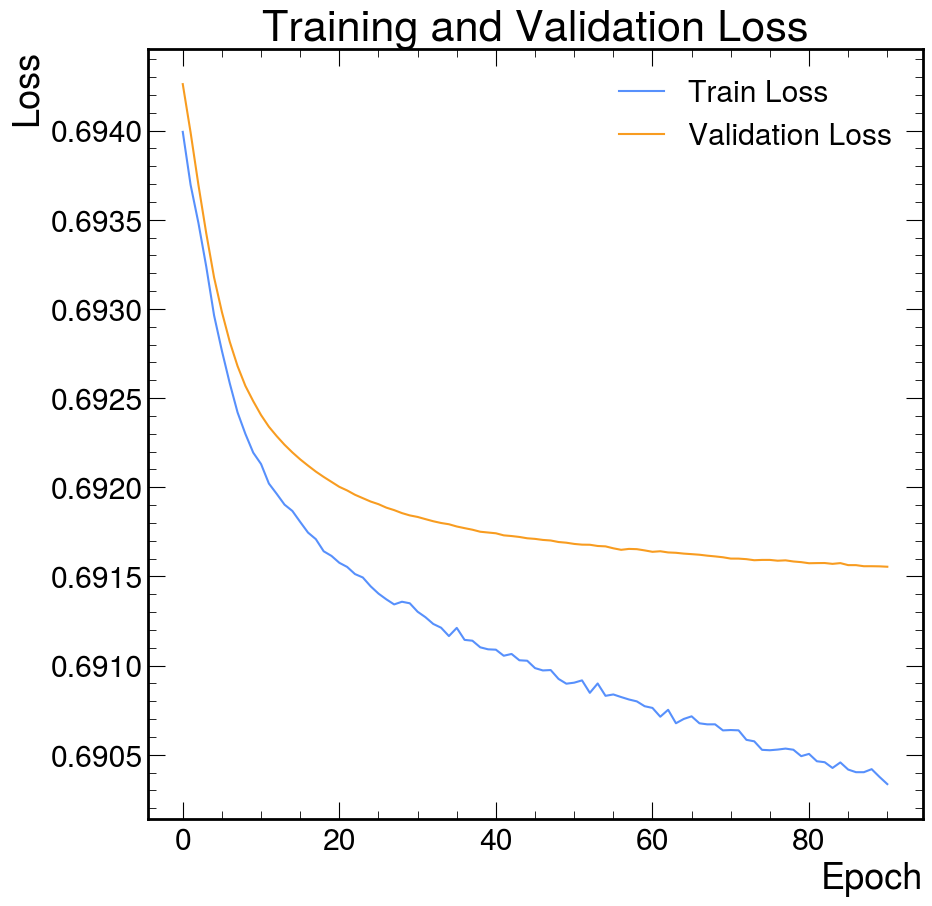

91 Training Loss: 0.6903
91 Validation Loss: 0.6916
92 Training Loss: 0.6903
92 Validation Loss: 0.6916
93 Training Loss: 0.6903
93 Validation Loss: 0.6915
94 Training Loss: 0.6903
94 Validation Loss: 0.6915
95 Training Loss: 0.6903
95 Validation Loss: 0.6916
96 Training Loss: 0.6902
96 Validation Loss: 0.6915
97 Training Loss: 0.6903
97 Validation Loss: 0.6915
98 Training Loss: 0.6903
98 Validation Loss: 0.6915
99 Training Loss: 0.6903
99 Validation Loss: 0.6915


In [41]:
from torch.optim import RAdam

model = DCTRNet(input_dim=x_tensor.shape[1], hidden_net=[64,64,64]).to("cuda")

opt = RAdam(model.parameters(), lr=0.00001)

train_loss, val_loss = train(model, 100, train_loader, val_loader, opt, device="cuda" if torch.cuda.is_available() else "cpu")

In [42]:
with torch.no_grad():
    y_pred = torch.sigmoid(model(x_tensor.to('cuda'))).squeeze().to('cpu')

Text(1, 0, 'classifier output')

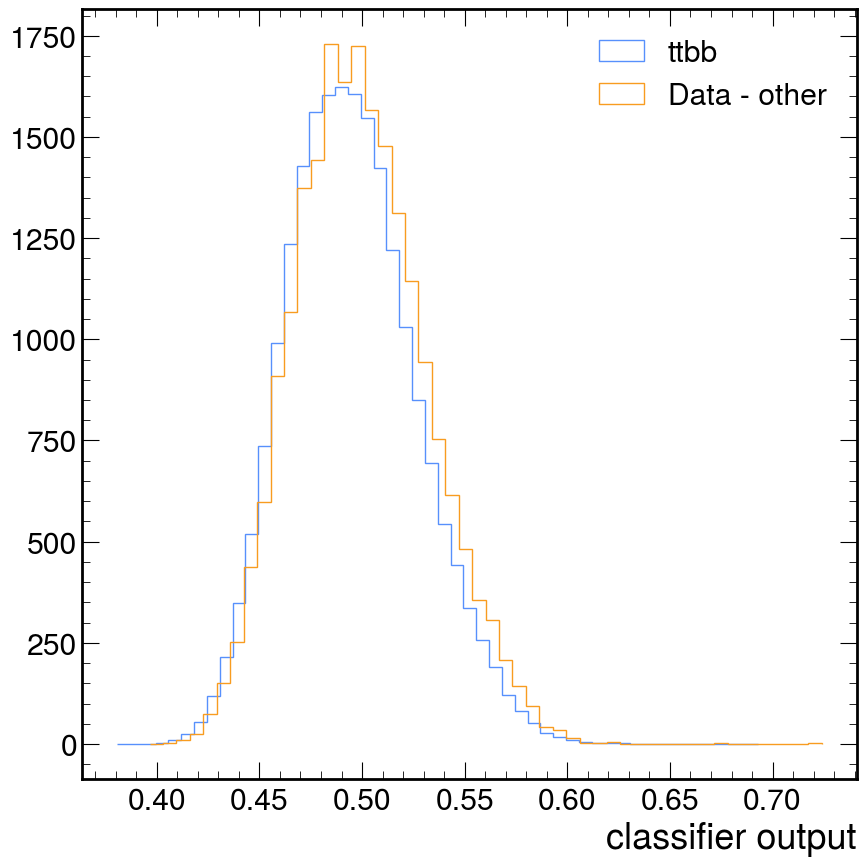

In [43]:
plt.hist(y_pred.detach().cpu().numpy()[target==0], weights=training_weight[target==0], bins=50, histtype="step", label="ttbb")
plt.hist(y_pred.detach().cpu().numpy()[target==1], weights=training_weight[target==1], bins=50, histtype="step", label="Data - other")
plt.legend()
plt.xlabel("classifier output")

In [58]:
dctr_w = y_pred / (1-y_pred)

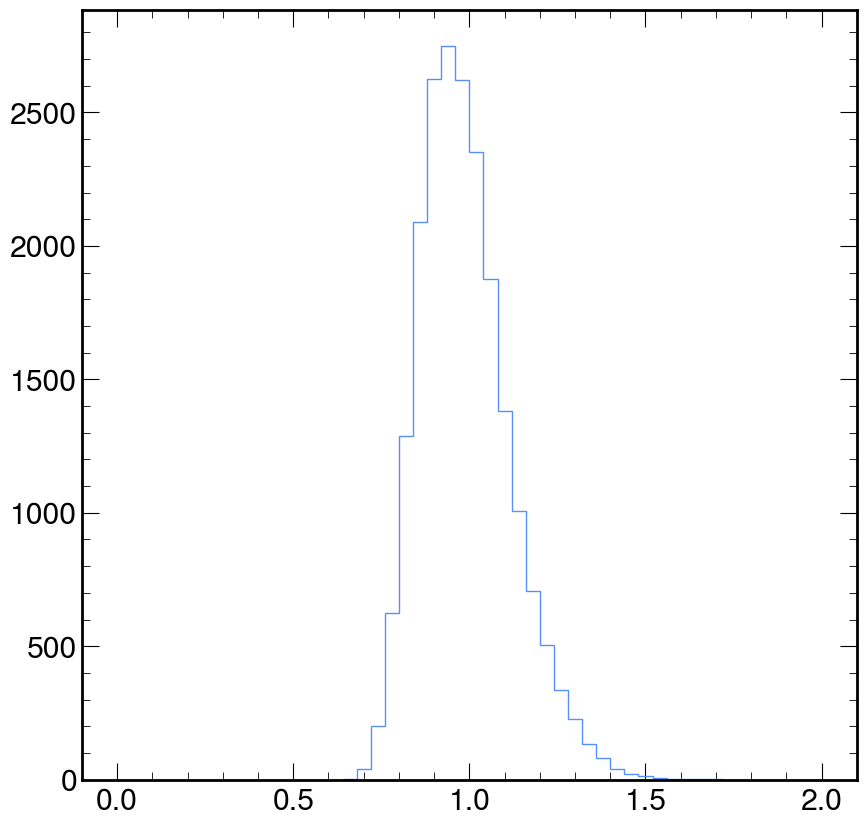

In [46]:
plt.hist(dctr_w.detach().cpu().numpy()[target==0], weights=training_weight[target==0], range=(0, 2), bins=50, histtype="step", label="ttbb");
#plt.yscale("log")

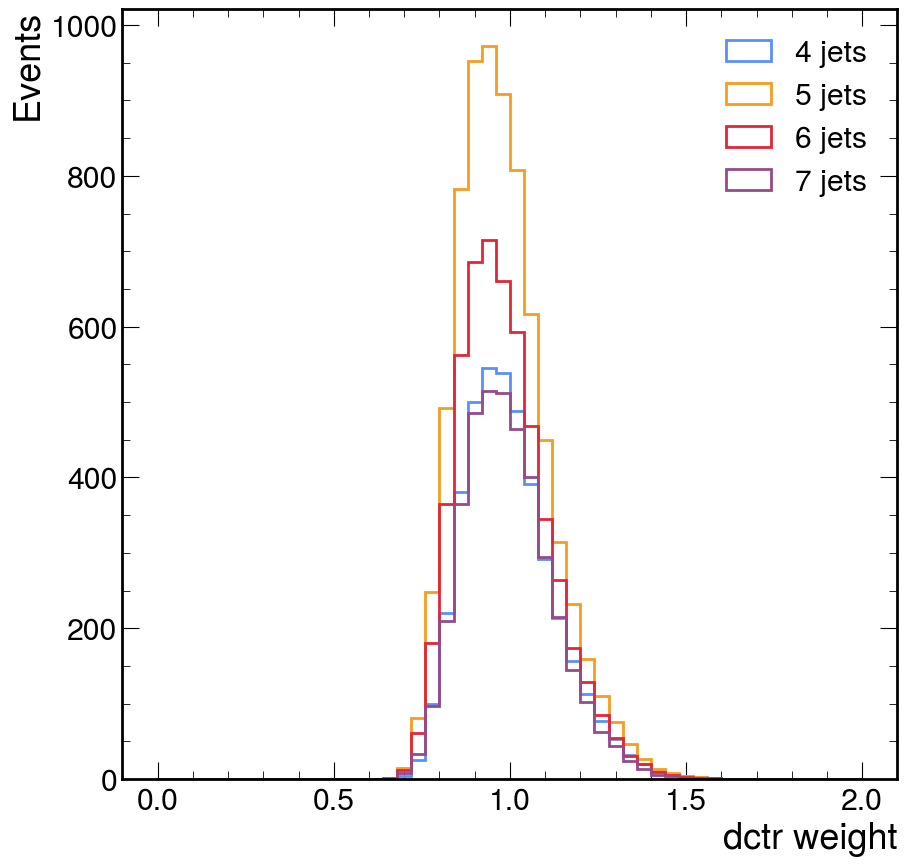

In [ ]:
# plot dctr weight for different njets
plt.figure()
for nj in range(4,8):
    if nj ==7:
        mask_nj = ak.to_numpy(njet[mask_ttbb_CR] >= nj)
    else:
        mask_nj = ak.to_numpy(njet[mask_ttbb_CR] == nj)
    
    
    plt.hist(dctr_w.detach().cpu().numpy()[(target==0) & mask_nj], weights=training_weight[(target==0) & mask_nj], range=(0, 2), bins=50, histtype="step", linewidth=2, label=f"{nj} jets");
plt.xlabel("dctr weight")
plt.ylabel("Events")
plt.legend()
plt.show()

In [64]:
# dctr w to numpy
dctr_weight = dctr_w.detach().cpu().numpy()
dctr_weight

array([1.0585725, 1.0866473, 1.165967 , ..., 0.897554 , 1.0263532,
       1.360057 ], dtype=float32)

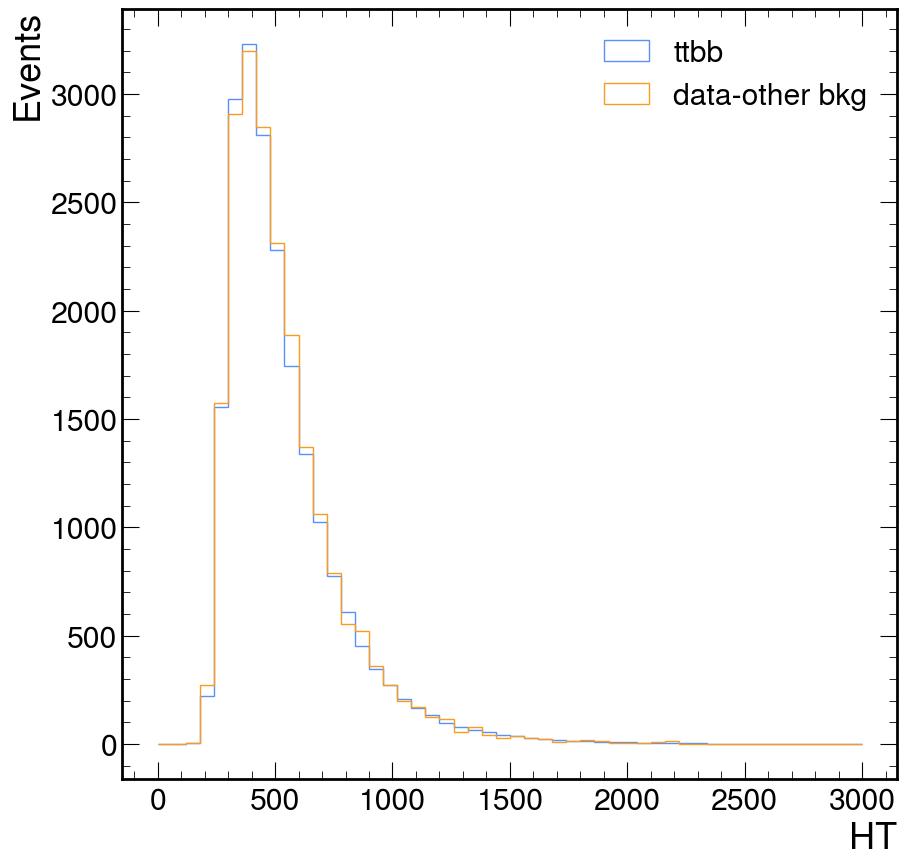

In [63]:
# rescale ht histogram for ttbb to data-other bkg in ttbb cr and by dctr weight
ht = df.events.ht[mask_ttbb_CR]
plt.hist(ht[target==0], weights=training_weight[target==0]*dctr_weight[target==0], bins=50, range=(0, 3000), histtype="step", label="ttbb");
plt.hist(ht[target==1], weights=training_weight[target==1], bins=50, range=(0, 3000), histtype="step", label="data-other bkg");
plt.xlabel("HT")
plt.ylabel("Events")
plt.legend()
plt.show()

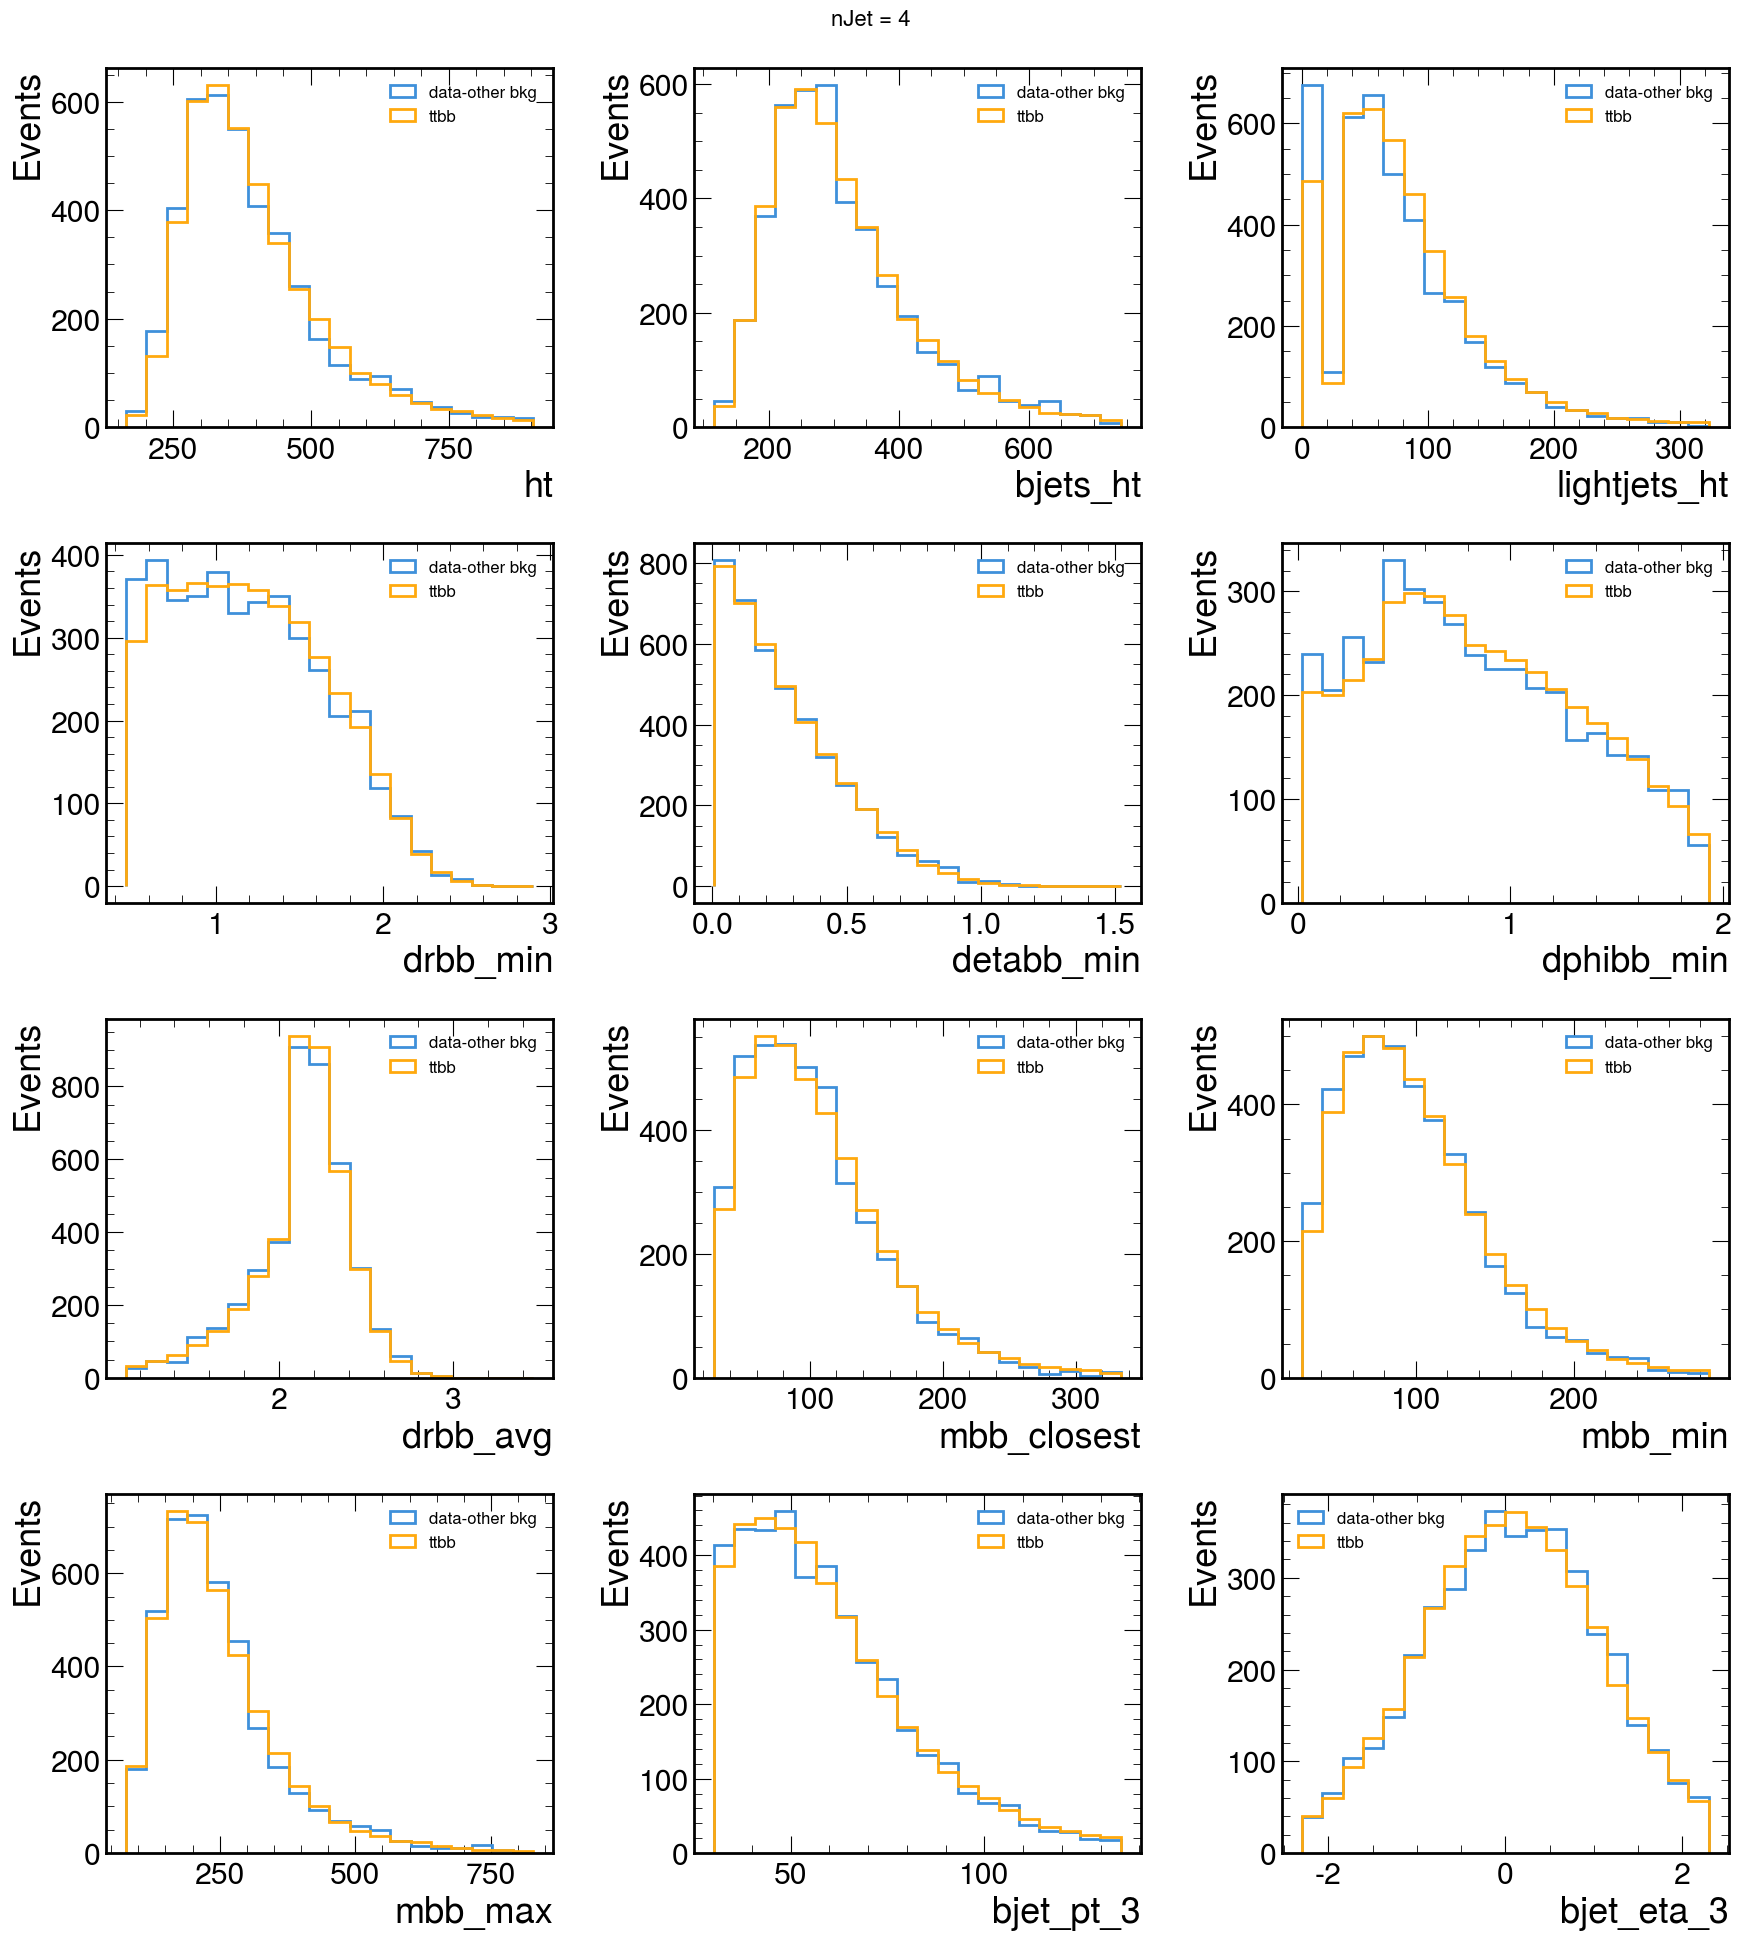

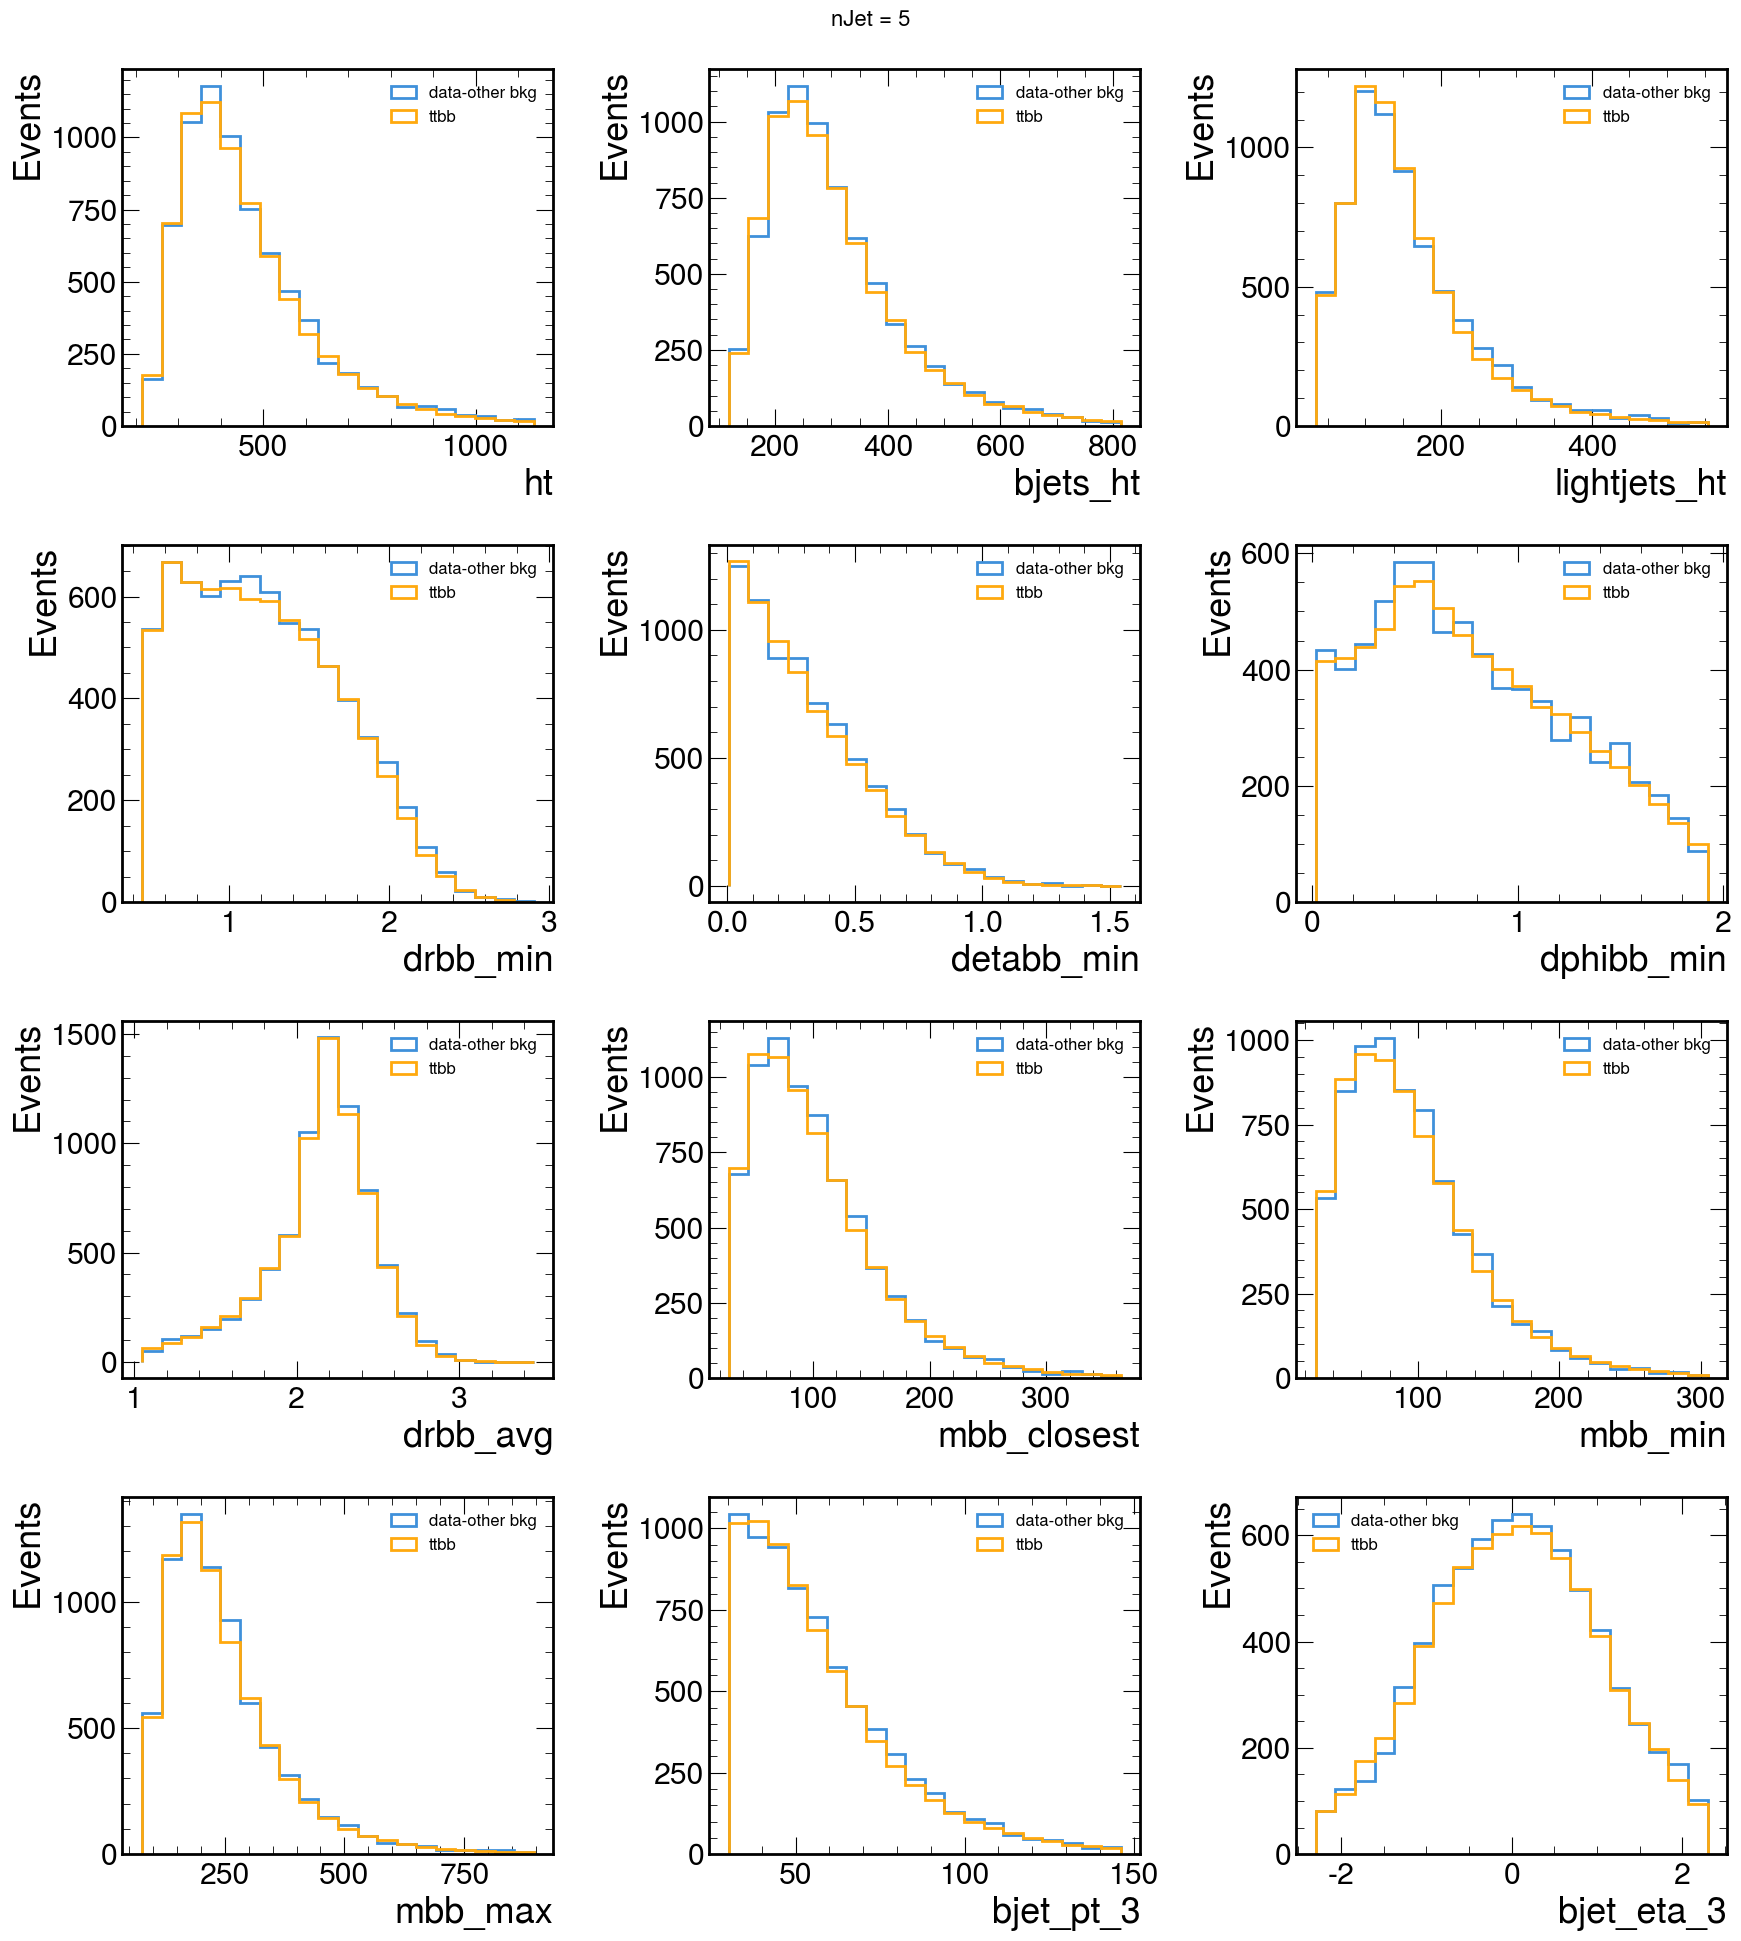

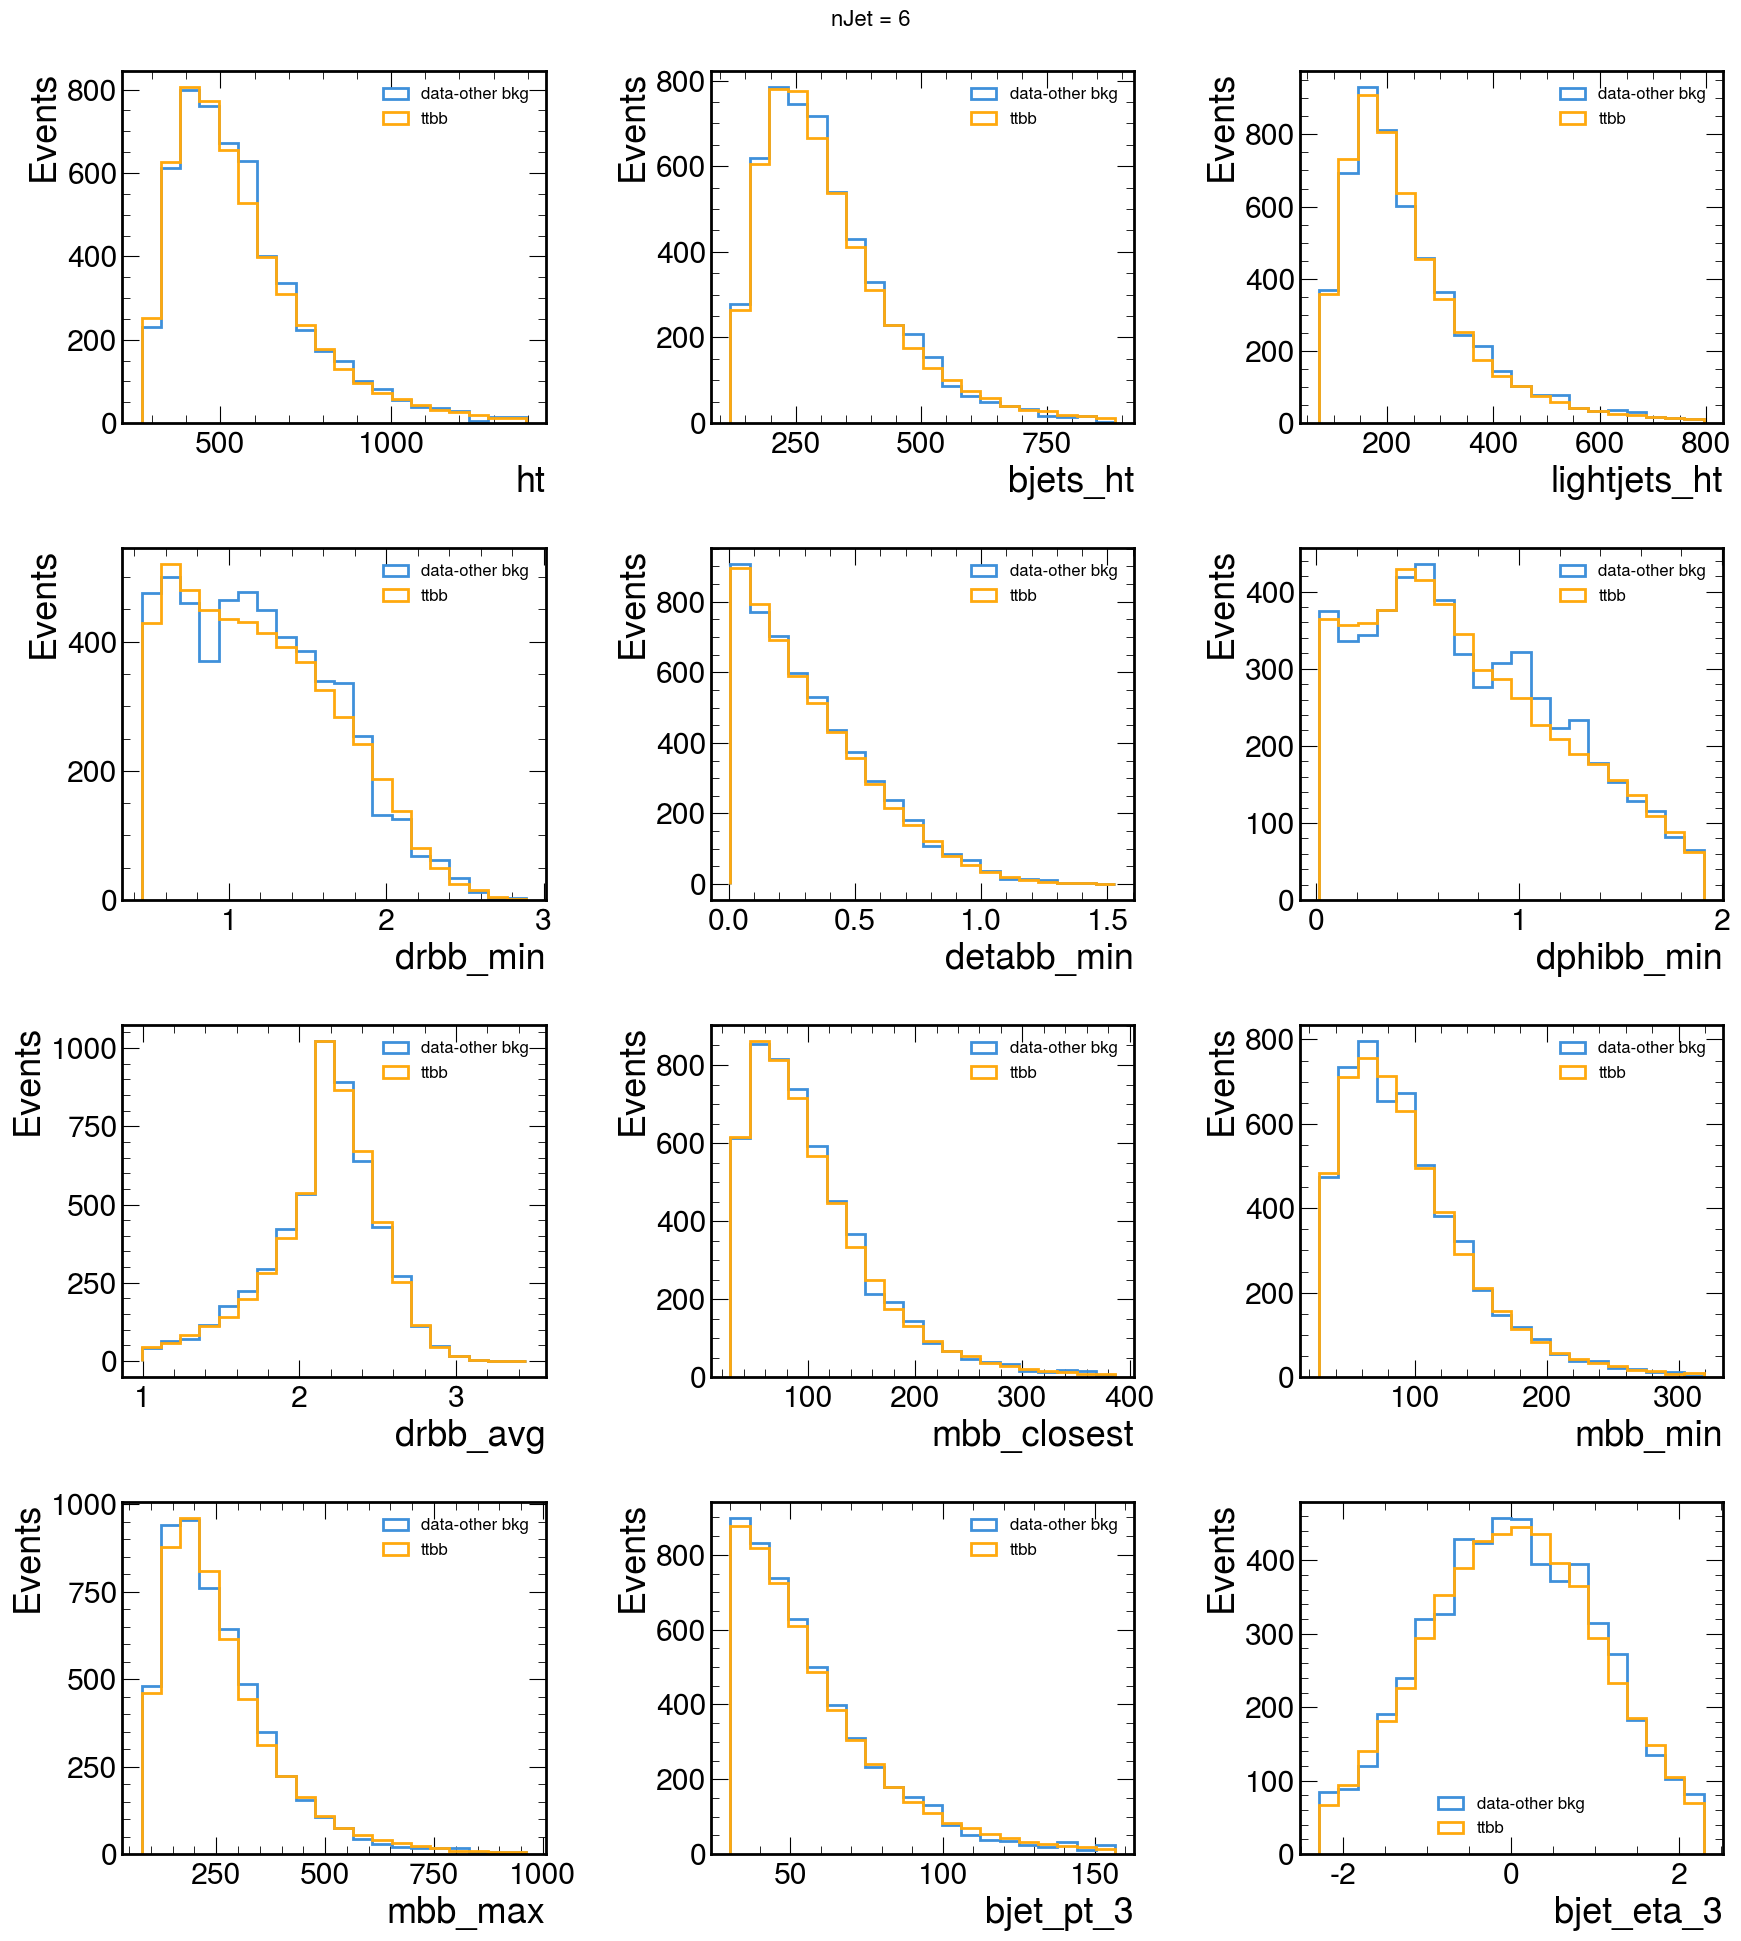

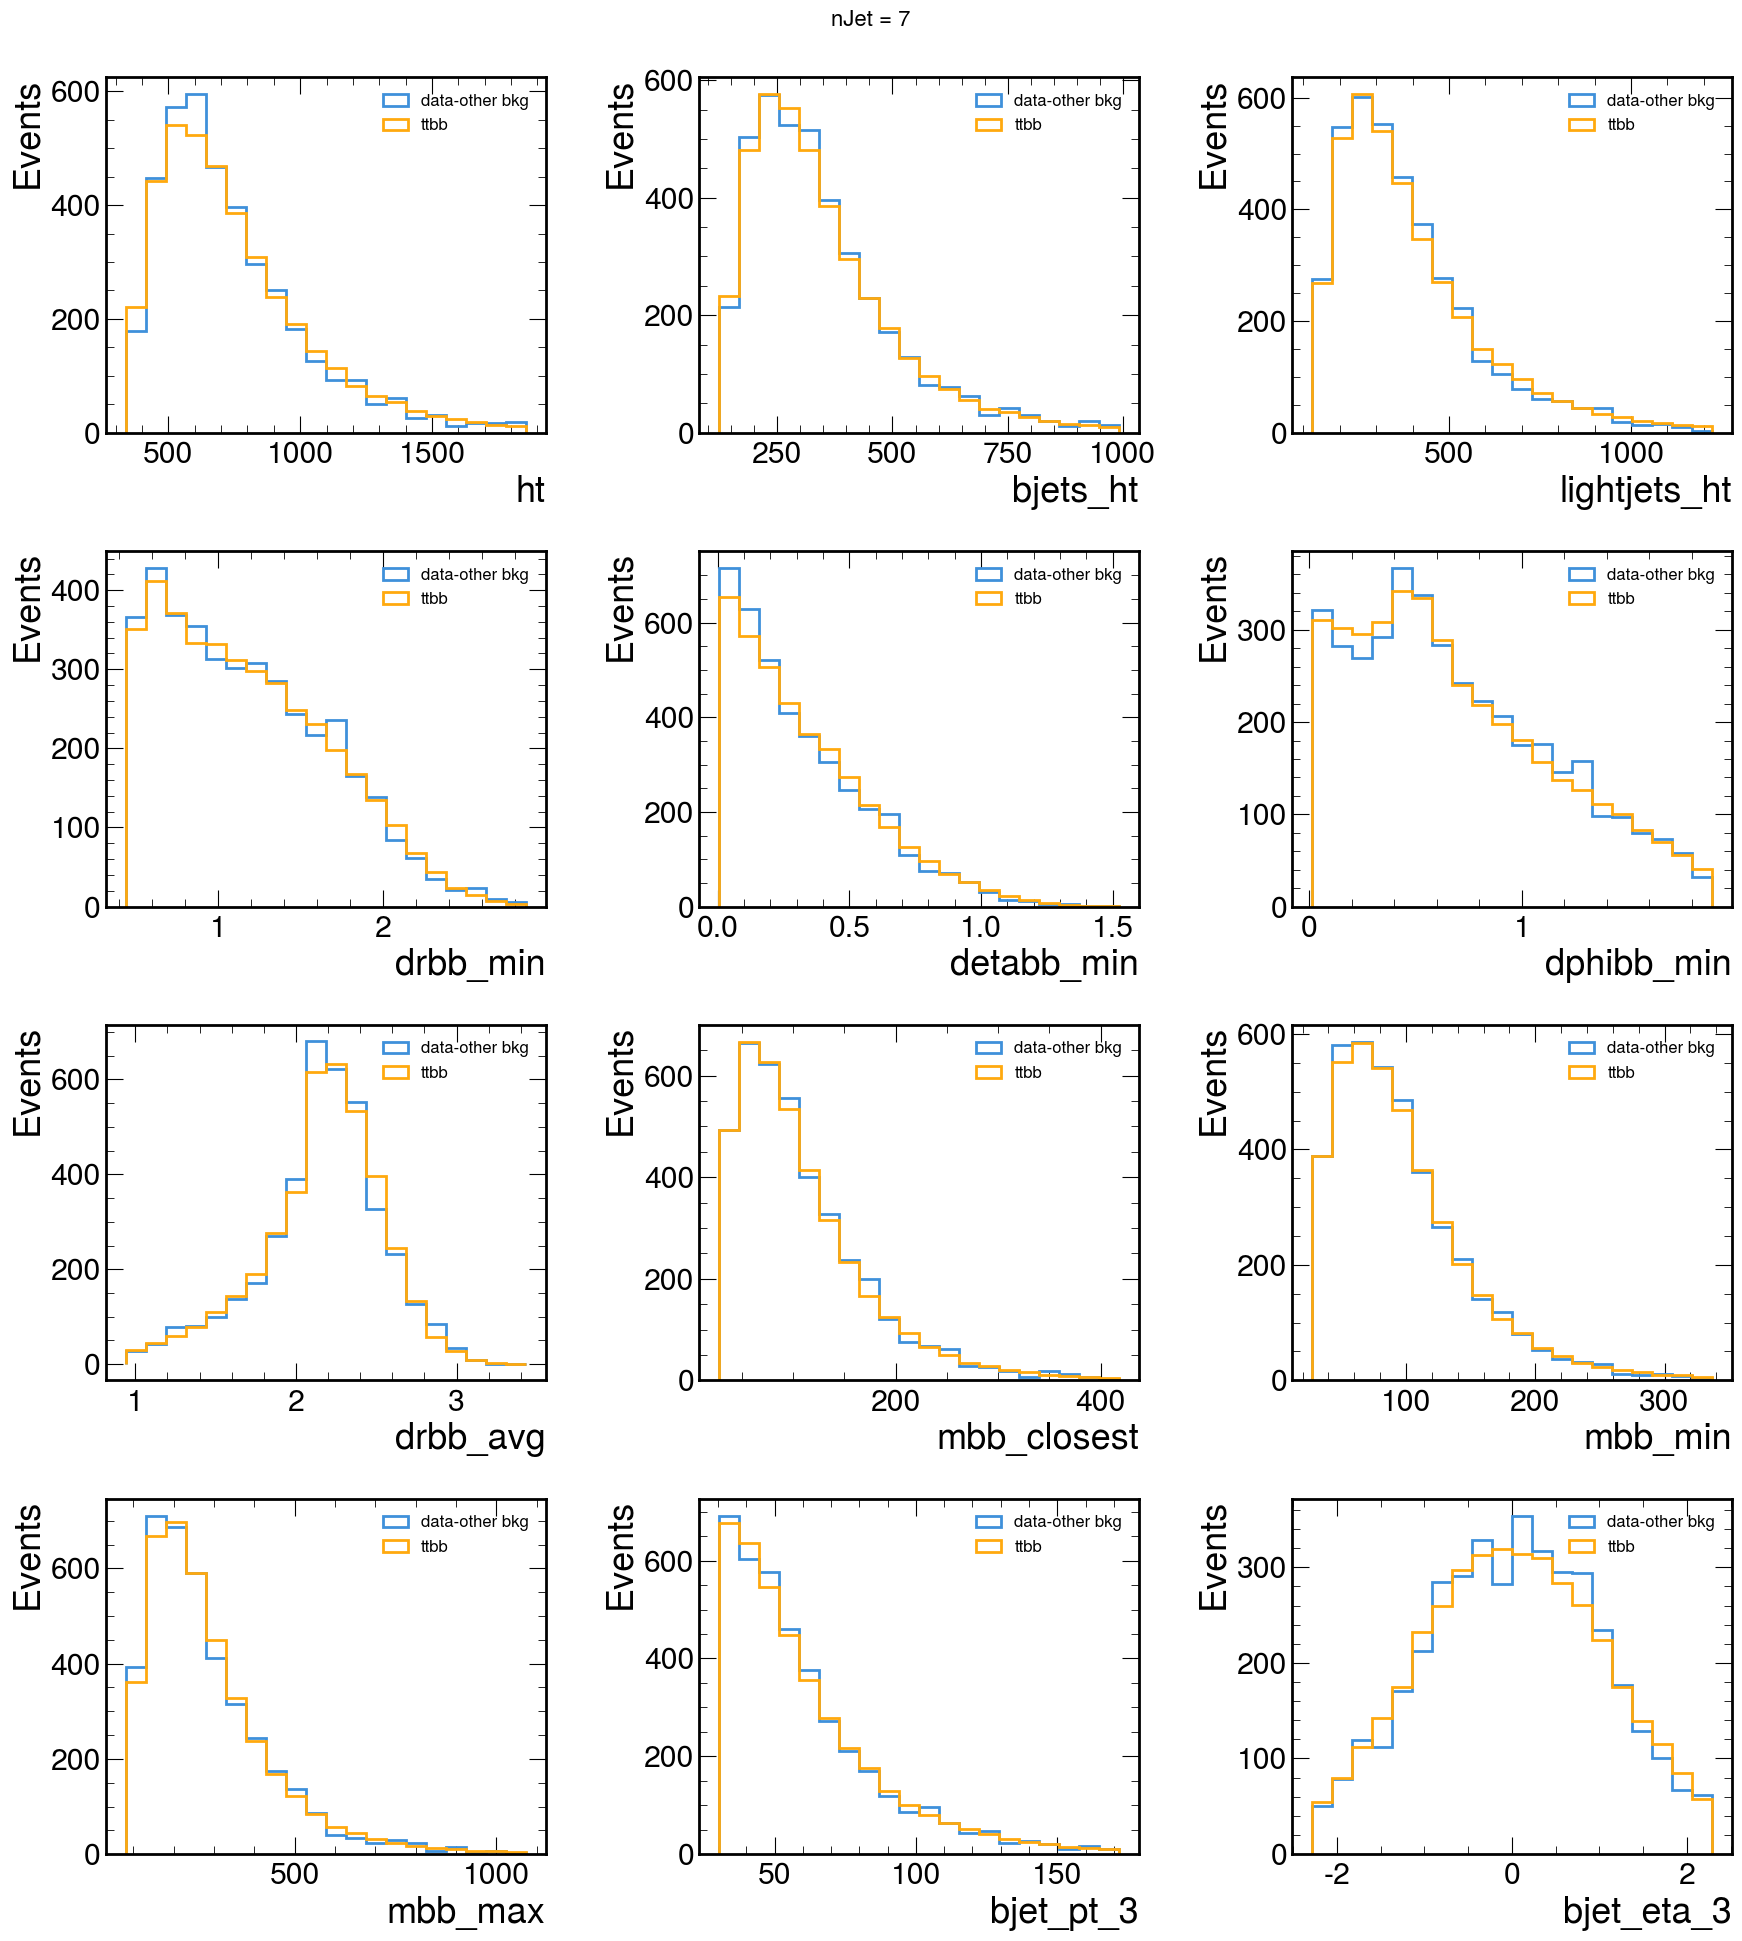

In [68]:
# reproduce the dctr inputs histograms with reweighted ttbb
fields = list(df.events.fields) + ["bjet_pt_3", "bjet_eta_3"]
n_fields = len(fields)
ncols = 3
nrows = (n_fields + ncols - 1) // ncols

# Create full-size dctr_weight array for easier indexing
dctr_weight_full = np.zeros(len(is_data))
dctr_weight_full[mask_ttbb_CR] = dctr_weight

# Create full-size rew_N_jets array for ttbb events
rew_N_jets_full = np.ones(len(is_data))
rew_N_jets_full[mask_ttbb_CR & (~is_data)] = rew_N_jets_ttbb

for nj in range(4, 8):
    if nj == 7:
        mask_nj = ak.to_numpy(njet >= nj)
    else:
        mask_nj = ak.to_numpy(njet == nj)
    
    fig, axes = plt.subplots(nrows, ncols, figsize=[6*ncols, 5*nrows])
    axes = axes.flatten()
    
    for i, field in enumerate(fields):
        ax = axes[i]
        if field == "bjet_pt_3":
            var = bjet_pt_3
        elif field == "bjet_eta_3":
            var = bjet_eta_3
        else:
            var = df.events[field]
        
        # Compute range from data (using njet selection)
        var_np = ak.to_numpy(var[mask_nj])
        vmin, vmax = np.nanpercentile(var_np, [1, 99])
        
        # Combined masks: njet_mask AND (mask_dctr or ~mask_dctr)
        mask_dctr_nj = is_data & mask_nj & mask_ttbb_CR
        mask_ttbb_nj = (~is_data) & mask_nj & mask_ttbb_CR
        
        ax.hist(var[mask_dctr_nj], weights=weights[mask_dctr_nj], bins=20, range=(vmin, vmax), 
                histtype="step", linewidth=2, color=CMAP_10[0], label="data-other bkg")
        # rescale ttbb with njet reweighting and dctr weight
        ax.hist(var[mask_ttbb_nj], 
                weights=weights[mask_ttbb_nj] * rew_N_jets_full[mask_ttbb_nj] * dctr_weight_full[mask_ttbb_nj], 
                bins=20, range=(vmin, vmax), 
                histtype="step", linewidth=2, color=CMAP_10[1], label="ttbb")
        ax.set_xlabel(field)
        ax.set_ylabel("Events")
        ax.legend(fontsize=12)
    
    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    
    fig.suptitle(f"nJet = {nj}", fontsize=16)
    fig_name = os.path.join(save_folder, f"dctr_input_variables_{nj}Jets_reweighted.png")
    plt.savefig(fig_name, dpi=300)
    plt.tight_layout()
    plt.show()

In [77]:
# Split events in 33% quantiles of the DCTR weight
q = [1./3, 2./3] 
weight_cuts_dict = {}
for nj in range(4, 8):
    if nj == 7:
        mask_nj = ak.to_numpy(njet >= nj)
    else:
        mask_nj = ak.to_numpy(njet == nj)
    
    # Mask for ttbb events in ttbb_CR with specific njet
    mask_ttbb_nj = (~is_data) & mask_nj & mask_ttbb_CR
    
    # Get dctr weights for these events using full-size array
    weights_by_njet = dctr_weight_full[mask_ttbb_nj]
    
    # Calculate quantiles
    w_lo, w_hi = np.quantile(weights_by_njet, q)
    
    if nj == 7:
        weight_cuts_dict[f"njet>={nj}"] = [(0, w_lo), (w_lo, w_hi), (w_hi, 3)]
    else:
        weight_cuts_dict[f"njet={nj}"] = [(0, w_lo), (w_lo, w_hi), (w_hi, 3)]

weight_cuts_dict

{'njet=4': [(0, 0.9353789289792379),
  (0.9353789289792379, 1.0436167319615681),
  (1.0436167319615681, 3)],
 'njet=5': [(0, 0.9189627170562744),
  (0.9189627170562744, 1.0264906485875447),
  (1.0264906485875447, 3)],
 'njet=6': [(0, 0.9219486117362976),
  (0.9219486117362976, 1.0322153568267822),
  (1.0322153568267822, 3)],
 'njet>=7': [(0, 0.9371899167696635),
  (0.9371899167696635, 1.04704749584198),
  (1.04704749584198, 3)]}

In [106]:
#njet[mask_ttbb_CR]
#is_data[mask_ttbb_CR]
#mask_ttbb_CR
#ttbb_dctr_w = dctr_weight
#mask_ttbb_CR.shape
# take only ttbb events in ttbb cr
dctr_w_ttbb = dctr_weight[~is_data[mask_ttbb_CR]]
